**Table of Contents**<a id='toc0_'></a>    
1. [Setup](#toc1_)    
1.1. [Checklist](#toc1_1_)    
1.2. [Character Count Check](#toc1_2_)    
1.3. [Libraries](#toc1_3_)    
1.3.1. [Exploration](#toc1_3_1_)    
1.3.2. [K-Means](#toc1_3_2_)    
1.3.3. [DBSCAN](#toc1_3_3_)    
1.3.4. [GMM](#toc1_3_4_)    
1.3.5. [Spectral](#toc1_3_5_)    
2. [Dataset 1](#toc2_)    
2.1. [Exploration](#toc2_1_)    
2.1.1. [Observations](#toc2_1_1_)    
2.1.2. [Algorithm Strategy](#toc2_1_2_)    
2.2. [K-Means](#toc2_2_)    
2.2.1. [Best k](#toc2_2_1_)    
2.3. [DBSCAN](#toc2_3_)    
2.3.1. [Three-clusters](#toc2_3_1_)    
2.3.2. [DBSCAN Failure](#toc2_3_2_)    
2.4. [HDBSCAN (Can Adaptive Density Help?)](#toc2_4_)    
2.5. [OPTICS](#toc2_5_)    
2.6. [Spectral Clustering](#toc2_6_)    
2.6.1. [Three-clusters](#toc2_6_1_)    
2.7. [Gaussian Mixture Models (GMM)](#toc2_7_)    
2.8. [Agglomerative](#toc2_8_)    
2.8.1. [Why HDBSCAN works but Agglomerative fails?](#toc2_8_1_)    
2.9. [Conclusion](#toc2_9_)    
3. [Dataset 2](#toc3_)    
3.1. [Exploration](#toc3_1_)    
3.1.1. [Dimensionality Reduction](#toc3_1_1_)    
3.1.2. [Observations](#toc3_1_2_)    
3.1.3. [Algorithm Strategy](#toc3_1_3_)    
3.2. [K-Means](#toc3_2_)    
3.2.1. [K-Means on Top Two Components by PCA](#toc3_2_1_)    
3.3. [Gaussian Mixture Models (GMM)](#toc3_3_)    
3.3.1. [Best Model Selection](#toc3_3_1_)    
3.3.2. [Random Initialization](#toc3_3_2_)    
3.3.3. [GMM Stability](#toc3_3_3_)    
3.4. [DBSCAN](#toc3_4_)    
3.5. [HDBSCAN](#toc3_5_)    
3.6. [Spectral Clustering](#toc3_6_)    
3.7. [Conclusion](#toc3_7_)    
3.7.1. [t-SNE Visualization](#toc3_7_1_)    
4. [Dataset 3](#toc4_)    
4.1. [Exploration](#toc4_1_)    
4.1.1. [Observations](#toc4_1_1_)    
4.1.2. [Algorithm Strategy](#toc4_1_2_)    
4.2. [K-Means](#toc4_2_)    
4.3. [DBSCAN](#toc4_3_)    
4.3.1. [DBSCAN as noise removal for K-Means](#toc4_3_1_)    
4.4. [OPTICS](#toc4_4_)    
4.5. [HDBSCAN](#toc4_5_)    
4.6. [Spectral Clustering](#toc4_6_)    
4.7. [GMM](#toc4_7_)    
4.7.1. [DBSCAN as noise removal for GMM](#toc4_7_1_)    
4.8. [Agglomerative](#toc4_8_)    
4.9. [Conclusion](#toc4_9_)    
5. [Dataset 4](#toc5_)    
5.1. [Exploration](#toc5_1_)    
5.1.1. [Feature Scaling](#toc5_1_1_)    
5.1.2. [Observations](#toc5_1_2_)    
5.1.3. [Algorithm Strategy](#toc5_1_3_)    
5.2. [K-Means](#toc5_2_)    
5.3. [DBSCAN](#toc5_3_)    
5.4. [HDBSCAN](#toc5_4_)    
5.5. [Spectral Clustering](#toc5_5_)    
5.6. [Agglomerative](#toc5_6_)    
5.7. [Conclusion](#toc5_7_)    
6. [Overall Results and Conclusions](#toc6_)    
7. [References](#toc7_)    
7.1. [Libraries](#toc7_1_)    
7.2. [Environment (pyproject.toml)](#toc7_2_)    
7.3. [Algorithms](#toc7_3_)    
7.3.1. [Selection Rationale](#toc7_3_1_)    
7.3.1.1. [Algorithms Used](#toc7_3_1_1_)    
7.3.1.2. [Algorithms Considered But Not Used](#toc7_3_1_2_)    
7.3.2. [Computational Complexity](#toc7_3_2_)    
7.3.3. [References](#toc7_3_3_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=true
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# 1. <a id='toc1_'></a>[Setup](#toc0_)
## 1.1. <a id='toc1_1_'></a>[Checklist](#toc0_)

| Item | Status |
|-------|-------|
| ipynb | Yes |
| output | Yes |
| pdf | Yes |
| list of libraries (end) | Yes |
| Numbering each header | Yes |
| TOC | Yes |
| count_char run | Yes |
| count_char output | Yes |
| <75k | Yes |

## 1.2. <a id='toc1_2_'></a>[Character Count Check](#toc0_)

In [1]:
import json

def count_chars(filename):
    with open(filename) as f:
        nb = json.load(f)

    counts = {'code': 0, 'markdown': 0, 'raw': 0, 'other': 0}

    for cell in nb['cells']:
        cell_type = cell['cell_type']
        chars = sum(len(line) for line in cell['source'])

        if cell_type in counts:
            counts[cell_type] += chars
        else:
            counts['other'] += chars

    total = sum(counts.values())

    for cell_type in ['code', 'markdown', 'raw', 'other']:
        print(f"{cell_type},{counts[cell_type]}")

    print(f"total,{total}")

    if total > 75000:
        print("Too many characters in assignment submission (> 75,000)")
    else:
        print("Number of characters ok (< 75,000)")


count_chars('cml.ipynb')

code,22873
markdown,43419
raw,0
other,0
total,66292
Number of characters ok (< 75,000)


## 1.3. <a id='toc1_3_'></a>[Libraries](#toc0_)

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import seaborn as sns

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering, HDBSCAN, OPTICS, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

In [3]:
import warnings

warnings.filterwarnings("ignore", message=r".*default value of `copy` will change from False to True.*", category=FutureWarning)
warnings.filterwarnings("ignore", message="Graph is not fully connected*", category=UserWarning)

RANDOM_STATE = 42

### 1.3.1. <a id='toc1_3_1_'></a>[Exploration](#toc0_)

In [4]:
def explore_2d(X, k=5):
    """Just plot the dataset (2D)
    Optionally take k for nearest
    neighbour distance analysis.
    Set k=0 to avoid plotting it
    """
    print(f"Shape: {X.shape}, x: ({X[:, 0].min():.2f}, {X[:, 0].max():.2f}), y: ({X[:, 1].min():.2f}, {X[:, 1].max():.2f})")

    _fig, axs = plt.subplots(1, 2 if k > 0 else 1, figsize=(12 if k > 0 else 6, 6))
    if k <= 0:
        axs = [axs]

    axs[0].scatter(X[:, 0], X[:, 1], s=1)
    axs[0].set_title("Dataset")
    axs[0].set_xlabel('x')
    axs[0].set_ylabel('y')

    if k > 0:
        nn = NearestNeighbors(n_neighbors=k).fit(X)
        dist = np.sort(nn.kneighbors(X)[0][:, k-1])
        axs[1].plot(dist)
        axs[1].set_title(f"Kth Neighbour Distance (k={k})")
        axs[1].set_xlabel("Points")
        axs[1].set_ylabel(f"Distance to {k}th neighbour")

    plt.show()

### 1.3.2. <a id='toc1_3_2_'></a>[K-Means](#toc0_)

In [5]:
def plot_kmeans(X, kms, silhouettes, plot_ks):
    """Plot utility for K-Means.
    Easy comparison in one place
    """
    _fig, axs = plt.subplots(1, len(plot_ks), figsize=(6 * len(plot_ks), 6))

    if len(plot_ks) == 1: axs = [axs]

    for i, k in enumerate(plot_ks):
        km = kms[k]
        silhouette = silhouettes[k]
        axs[i].scatter(X[:, 0], X[:, 1], c=km.labels_, s=1)
        axs[i].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c=range(k), s=100)
        axs[i].set_title(f"k={k}, silhoutte={silhouette:.2f}")
        axs[i].set_xlabel('x')
        axs[i].set_ylabel('y')

    plt.show()

def get_kmeans_metrics(X, ks, plot_ks=None):
    """Fits K-Means for given values of
    ks, compute silhouette and intertia
    metrics, and plot selected ks.
    """
    kms = {k: KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X) for k in ks}
    labels = {k: km.labels_ for k, km in kms.items()}
    inertias = {k: km.inertia_ for k, km in kms.items()}
    silhouettes = {k: silhouette_score(X, km.labels_) if k > 1 else np.nan for k, km in kms.items()}

    # By default, plot all k
    if plot_ks is None:
        plot_ks = ks

    if len(plot_ks) > 0:
        plot_kmeans(X, kms, silhouettes, plot_ks)

    return kms, labels, inertias, silhouettes

In [6]:
def find_plot_best_k(ks, X, kms, inertias, silhouettes, plot_ks=1):
    """Find the best k from given K-Means
    by running elbow method and comparing
    silhoutte scores. Try to plot best ks
    using the silhoutte score since elbow
    is a more visual selection"""
    _fig, axs = plt.subplots(1, 2 + plot_ks, figsize=(4 * (2 + plot_ks), 4))

    # Elbow
    axs[0].plot(ks, [inertias[k] for k in ks], marker='.')
    axs[0].set_title("Elbow Method")
    axs[0].set_xlabel("k")
    axs[0].set_ylabel("Inertia")

    # Silhouette
    axs[1].plot(ks, [silhouettes[k] for k in ks], marker='.')
    axs[1].set_title("Silhouette Score")
    axs[1].set_xlabel("k")
    axs[1].set_ylabel("Score")

    # sort ks by best silhouette
    top_ks = sorted(ks, key=lambda k: silhouettes[k], reverse=True)[:plot_ks]
    for i, k in enumerate(top_ks):
        km = kms[k]
        silhouette = silhouettes[k]
        axs[2 + i].scatter(X[:, 0], X[:, 1], c=km.labels_, s=1)
        axs[2 + i].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c=range(k), s=100)
        axs[2 + i].set_title(f"k={k}, silhoutte={silhouette:.2f}")
        axs[2 + i].set_xlabel('x')
        axs[2 + i].set_ylabel('y')

    plt.show()
    print(f"Highest silhouette score for k={top_ks[0]}")

### 1.3.3. <a id='toc1_3_3_'></a>[DBSCAN](#toc0_)

In [7]:
def plot_dbscan(X, models, keys, clusters, noises, silhouettes, dbi, chi, key_name='eps'):
    """Plot utility for models.
    Easy comparing in one place
    """
    def fmt_key(k):
        if isinstance(k, tuple):
            return "(" + ", ".join(fmt_key(x) for x in k) + ")"
        if hasattr(k, "item"): k = k.item()
        return f"{k:.2f}" if isinstance(k, float) else str(k)

    _fig, axs = plt.subplots(1, len(keys), figsize=(4 * len(keys), 4))

    for key, ax in zip(keys, axs):
        db = models[key]
        ax.scatter(X[:, 0], X[:, 1], c=db.labels_, s=1)

        ax.set_title(f"{key_name}={fmt_key(key)}, clusters={clusters[key]}, noise={noises[key]},\ns={silhouettes[key]:.2f}, dbi={dbi[key]:.2f}, chi={chi[key]:.2f}")

        ax.set_xlabel('x')
        ax.set_ylabel('y')

    plt.show()

def get_dbscan_metrics(X, models, keys, key_name='eps', plot_keys=None):
    """Calculate metrics for given dataset
    and labels. Also, ensure that at least
    two clusters are observed in labels"""
    labels = {key: db.labels_ for key, db in models.items()}

    # Gete valid clusters for model.
    # DBSCAN assigns noise label=-1.
    clusters = {key: len(set(label) - {-1}) for key, label in labels.items()}
    noises = {key: int(np.sum(label == -1)) for key, label in labels.items()}

    masks = {key: label != -1 for key, label in labels.items()}

    # Calculate the clustering metrics
    # Do not include noises in metrics
    silhouettes = {key: silhouette_score(X[mask], labels[key][mask]) if clusters[key] > 1 else np.nan for key, mask in masks.items()}
    dbi = {key: davies_bouldin_score(X[mask], labels[key][mask]) if clusters[key] > 1 else np.nan for key, mask in masks.items()}
    chi = {key: calinski_harabasz_score(X[mask], labels[key][mask]) if clusters[key] > 1 else np.nan for key, mask in masks.items()}

    # Display in a nice table
    df = pd.DataFrame([(key, clusters[key], round(dbi[key], 2), round(chi[key], 2), round(silhouettes[key], 2), noises[key]) for key in keys],
                      columns=[key_name, 'Clusters', 'DBI', 'CHI', 'Silhouette', 'Noise'])
    display(df)

    if plot_keys is None:
        plot_keys = keys

    if len(plot_keys) > 0:
        plot_dbscan(X, models, keys, clusters, noises, silhouettes, dbi, chi, key_name)

    # Not the best way to return from a function
    return labels, clusters, noises, silhouettes, dbi, chi

In [8]:
def plot_dbscan_metrics(keys, dbi, chi, silhouettes, noises, key_name='eps'):
    """Plot the various DBSCAN
    metrics vs given parameter
    """
    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.plot(keys, dbi.values(), label='DBI', marker='o')
    ax1.plot(keys, chi.values(), label='CHI', marker='.')
    ax1.plot(keys, silhouettes.values(), label='Silhouette', marker='.')

    ax1.set_xlabel(key_name)
    ax1.set_ylabel('Metric Value')
    ax1.set_title(f'Metrics vs {key_name}')
    ax1.legend(loc='upper left')
    ax1.grid(True)

    ax2 = ax1.twinx()

    ax2.plot(keys, noises.values(), label='Noise', marker='x', linestyle='--')
    ax2.set_ylabel('# Noise Points')
    ax2.legend(loc='upper right')

    plt.show()

### 1.3.4. <a id='toc1_3_4_'></a>[GMM](#toc0_)

In [9]:
def get_plot_gmm_metrics(X, gmms, key_name='k', plot_ks=None):
    """Calculate GMM metrics: aic,
    bic, and likelihood score and
    optionally plot v. # clusters
    """
    labels = {k: gmm.predict(X) for k, gmm in gmms.items()}
    bics = {k: gmm.bic(X) for k, gmm in gmms.items()}
    aics = {k: gmm.aic(X) for k, gmm in gmms.items()}
    scores = {k: gmm.score(X) for k, gmm in gmms.items()}

    if plot_ks is None:
        plot_ks = list(gmms.keys())

    if len(plot_ks) > 0:
        fig, axs = plt.subplots(1, len(plot_ks), figsize=(6 * len(plot_ks), 6))

        for i, k in enumerate(plot_ks):
            axs[i].scatter(X[:, 0], X[:, 1], c=labels[k], s=1)

            axs[i].set_title(f"GMM ({key_name}={k}, BIC={bics[k]:.2f}, AIC={aics[k]:.2f})")
            axs[i].set_xlabel('x')
            axs[i].set_ylabel('y')

        plt.show()

    # Plot AIC and BIC v key
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    fig.suptitle(f"GMM Selection: BIC and AIC vs {key_name}")

    ks = list(gmms.keys())

    # bic
    axs[0].plot(ks, [bics[k] for k in ks], marker='.')
    axs[0].set_xlabel("k")
    axs[0].set_ylabel("BIC")

    # aic
    axs[1].plot(ks, [aics[k] for k in ks], marker='.')
    axs[1].set_xlabel("k")
    axs[1].set_ylabel("AIC")

    plt.show()

    print(f"Best AIC score for k={min(bics, key=bics.get)}, score={aics[min(bics, key=bics.get)]:.2f}")
    print(f"Best BIC score for k={min(aics, key=aics.get)}, score={bics[min(aics, key=aics.get)]:.2f}")

    return labels, bics, aics, scores

### 1.3.5. <a id='toc1_3_5_'></a>[Spectral](#toc0_)

In [10]:
def plot_spectral_clustering(X, n_clusters, RANDOM_STATE, configs):
    """Calculate and plot spectral
    clustering for given config"""
    fig, axs = plt.subplots(1, len(configs), figsize=(4 * len(configs), 4))
    fig.suptitle(f"Spectral Clustering (n_clusters={n_clusters})")

    sc_labels = []

    for i, config in enumerate(configs):
        sc = SpectralClustering(n_clusters=n_clusters, random_state=RANDOM_STATE, **config).fit(X)

        axs[i].scatter(X[:, 0], X[:, 1], c=sc.labels_, s=1)

        title = config["affinity"]
        title += f", gamma={config['gamma']}" if title == "rbf" else f"={config.get('n_neighbors', 10)}"

        axs[i].set_title(title)
        axs[i].set_xlabel("x")
        axs[i].set_ylabel("y")

        sc_labels.append(sc.labels_)

    plt.show()

    return sc_labels

In [11]:
df1, df2, df3, df4 = [pd.read_csv(f"dataset{x}.csv") for x in range(1, 5)]

# 2. <a id='toc2_'></a>[Dataset 1](#toc0_)

## 2.1. <a id='toc2_1_'></a>[Exploration](#toc0_)

In [12]:
df1.describe()

,x,y
count,1100.000000,1100.000000
mean,0.276789,0.114015
std,1.791517,1.731823
min,-3.611348,-3.618315
25%,-0.831658,-0.467759
50%,0.453894,0.248911
75%,1.569590,0.923381
max,3.612618,3.596900


Shape: (1100, 2), x: (-3.61, 3.61), y: (-3.62, 3.60)


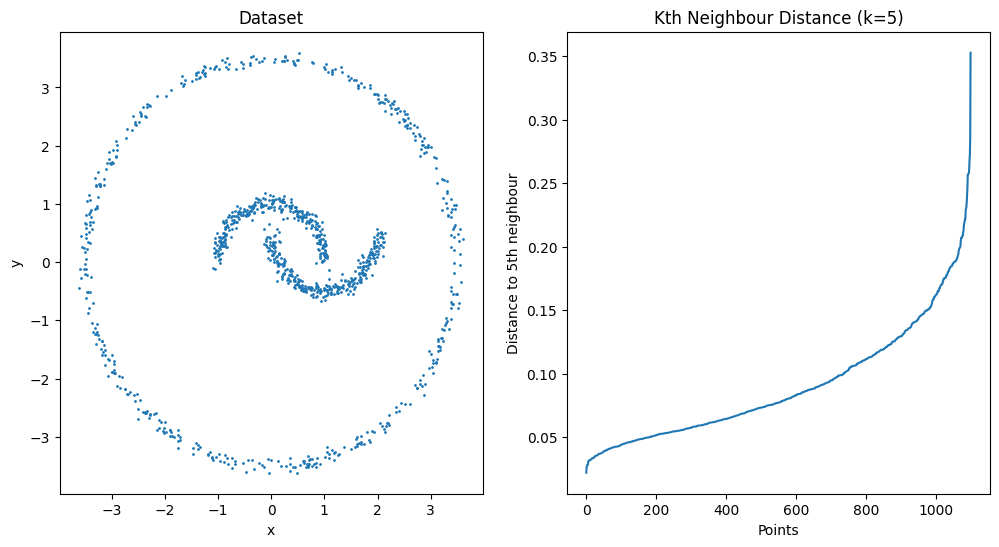

In [13]:
X = df1[['x', 'y']].to_numpy()
explore_2d(X)

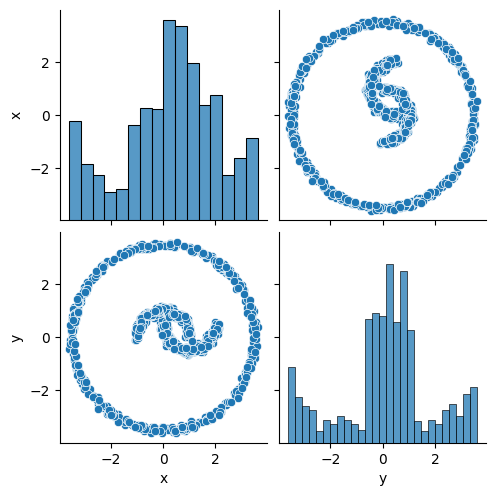

In [14]:
sns.pairplot(df1)
plt.show()

### 2.1.1. <a id='toc2_1_1_'></a>[Observations](#toc0_)
- No need to normalize since `x` and `y` are on similar scale.
- No missing or apparent anomalous data points.
- Data seems to be arranged in ring and semi-circles. In the absence of ground-truth, we can assume that the clusters should follow the same shapes. Hence one may consider **two or three clusters**.
- Kth neighbour distance shows elbow from 0.10 to 0.30

### 2.1.2. <a id='toc2_1_2_'></a>[Algorithm Strategy](#toc0_)
- **K-Means**: Baseline, shall perform poorly in non-convex space.  
- **DBSCAN**: Good candidate since it follows dense connectivity.
- **OPTICS**: Reasonable candidate as it is also density based that orders points based on reachability.
- **HDBSCAN**: Another great candidate, better than DBSCAN with varying density.
- **Spectral**: Great candiate as graph connectivity can capture non-linear boundaries.
- **GMM**: Check if assumption of gaussian distribution work.
- **Agglomerative**: Check if hierarchical merging respects given shape.

## 2.2. <a id='toc2_2_'></a>[K-Means](#toc0_)
K-Means assigns each point to the nearest centroid by minimizing distance. Hence, K-Means works well when clusters are convex. For non-convex data, K-Means is expected to perform poorly.

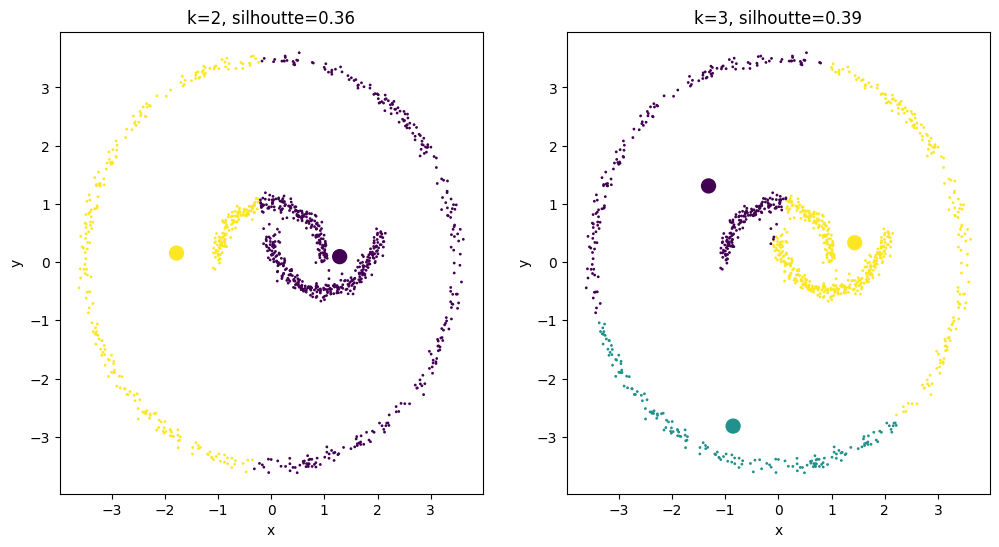

In [15]:
# Fit all K-Means models once
ks = range(2, 10)

kms, labels, inertias, silhouettes = get_kmeans_metrics(X, ks, [2, 3])

As expected, K-Means is not able to cluster properly in the non-convex space. Let's plot for the other values of `k` as well.

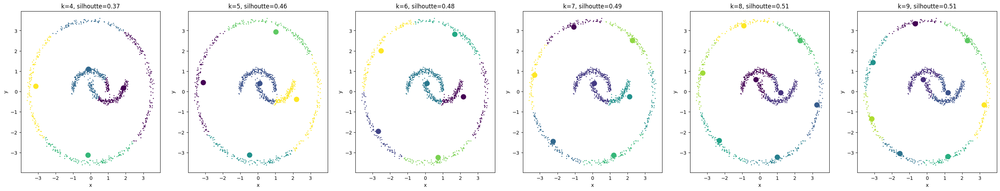

In [16]:
plot_kmeans(X, kms, silhouettes, [k for k in ks if k != 2 and k != 3])

### 2.2.1. <a id='toc2_2_1_'></a>[Best k](#toc0_)
We find best `k` by considering elbow method and looking at silhouette score. The elbow method determines cluster compactness by plotting sum of squared distances of points from their respective centroids for different values of `k`. Silhouette score, on the other hand, evaluates both compactness and separation by comparing the intra-cluster distance with the closest cluster distance for each point.

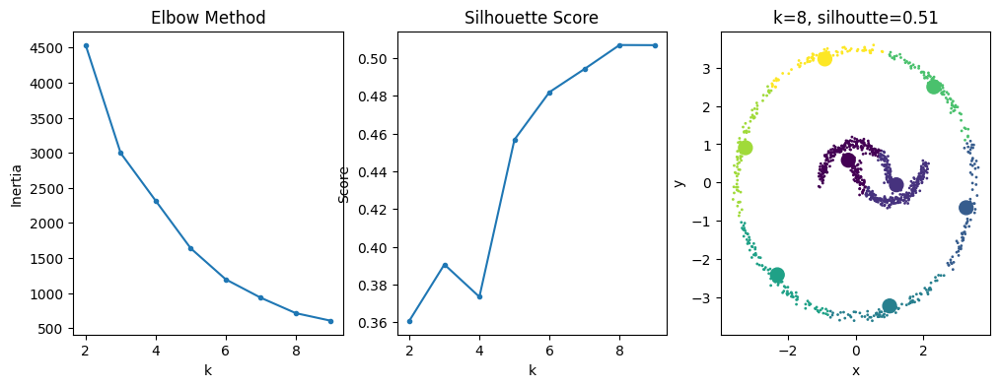

Highest silhouette score for k=8


In [17]:
find_plot_best_k(ks, X, kms, inertias, silhouettes)

`k=8` gives highest silhouette score but is visually incorrect. We get even higher silhouette (e.g. highest at `k~20`). But these are visually incorrect and can be attributed to metric rewarding the wrong thing (i.e. compactness of clusters) disregarding the underlying structure.

Let's try other methods.

## 2.3. <a id='toc2_3_'></a>[DBSCAN](#toc0_)
DBSCAN is a density-based clustering algorithm that groups together points that are closely packed and labels points in sparse regions as noise. The points seem to be fairly uniformly distributed in the ring and semi-circles, so DBSCAN is a good candidate as it can chain points along the contour. 

There are two important parameters - `eps` and `min_samples`. `eps` or epsilon is the maximum distance between two points for them to be considered neighbours. `min_samples` is mimimum number of points required within `eps` of a point to be considered a core point. In the absence of ground truth, we can't use hyperparameter optimization to tune these. Keeping `min_samples` as default initially given dataset's dimensionality (recommended >= 2\**dimensions* as per the original paper). Finding the right value `eps` is important - large enough to maintain continuity within cluster but small enough to avoid connecting two separate groups (e.g. the semi-circles and the ring). We shall use the kth neighbour distance (`k==min_samples`), to test for different values of `eps`. 

In [18]:
# N.B. After observing a dramatic change at 0.3
# let's do a local search to find the threshold
epses = [0.10, 0.15, 0.20, 0.25, 0.275, 0.2765, 0.277, 0.5]

dbs = {eps: DBSCAN(eps=eps).fit(X) for eps in epses}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, dbs, epses, plot_keys=[])

,eps,Clusters,DBI,CHI,Silhouette,Noise
0,0.1000,35,0.45,266.12,0.43,225
1,0.1500,24,0.49,622.75,0.40,52
2,0.2000,10,0.49,738.30,0.45,10
3,0.2500,8,0.51,884.47,0.50,0
4,0.2750,4,1.11,374.83,0.39,0
5,0.2765,3,1.65,279.09,0.36,0
6,0.2770,2,7.55,15.30,0.27,0
7,0.5000,2,7.55,15.30,0.27,0


To determine suitable value for `eps`, let's monitor additional metrics of quality of clustering:
- **Davies-Bouldin Index (DBI)** compares intra-cluster distance with inter-cluster separation (lower values are better).
- **Calinski-Harabasz Index (CHI)** evaluates cluster separation relative to cluster compactness (higher values are better).

Additionally, number of noise points are calculated. By plotting these metrics against `eps`, we can identify range where the clustering structure becomes stable. The optimal `eps` is chosen where clusters are visually correct, and the metrics indicate high-quality clustering.

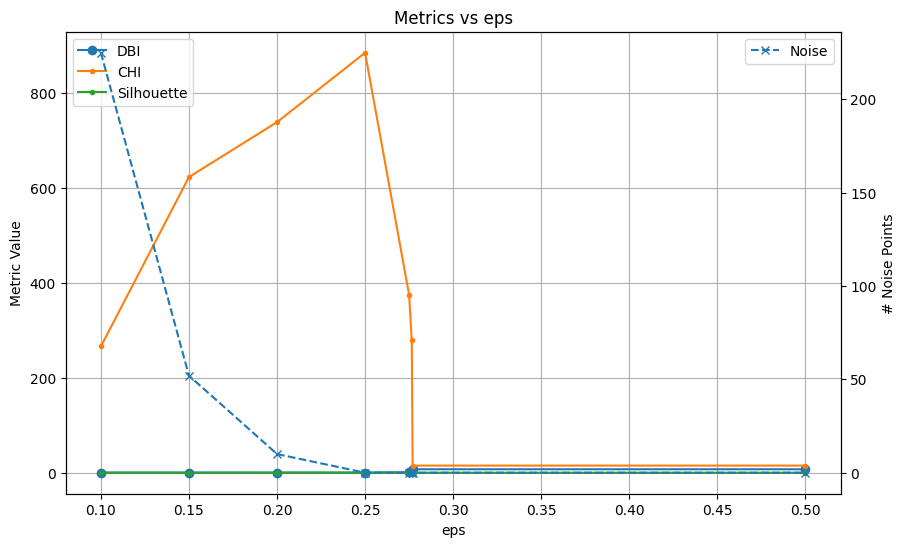

In [19]:
plot_dbscan_metrics(epses, dbi, chi, silhouettes, noises, 'eps')

The DBSCAN results became stable at `eps=0.277`. Increasing it beyond to this does not change the cluster assignments, noise points, or evaluation metrics. Larger `eps` doesn't create additional connections. This indicates that the clustering structure is **stable**.

While each metrics (Silhouette, DBI, and CHI) shows deterioration beyond this point, this behaviour is expected for DBSCAN on non-convex data. Our metrics assume compact, convex clusters and therefore are less reliable when applied to density-shaped structures (e.g. rings and semi-circles). In particular, once clusters become fully connected in a density sense, centroid-based metrics don't necessarily reflect meaningful clustering result.

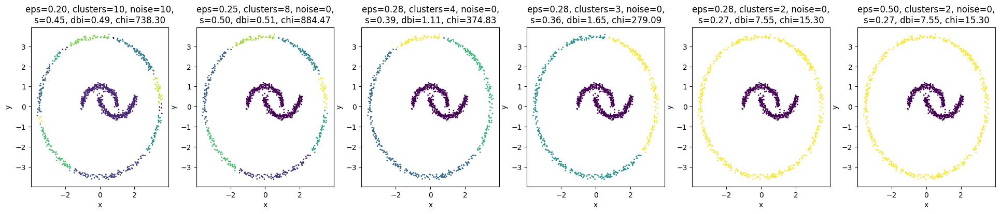

In [20]:
epses = [e for e in epses if 0.2 <= e]
plot_dbscan(X, dbs, epses, clusters, noises, silhouettes, dbi, chi)

Clustering changes from very fragmented with noise to connected regions that follow the underlying structure more closely as `eps` increases. At `eps=0.277`, the separation between the ring and inner semi-circles is already captured.

Hence, `eps=0.277` is chosen as the most appropriate clustering result visually for two clusters.

### 2.3.1. <a id='toc2_3_1_'></a>[Three-clusters](#toc0_)
However, the inner two semi-circles can be considered as two separate clusters. Let's see if DBSCAN can recover them. Let's try different values of `eps` and `min_samples`.

,"(eps, ms)",Clusters,DBI,CHI,Silhouette,Noise
0,"(0.1, 3)",52,0.49,273.94,0.40,100
1,"(0.11, 3)",46,0.50,337.33,0.39,68
2,"(0.12, 3)",39,0.51,416.95,0.37,42
3,"(0.13, 3)",35,0.52,474.24,0.38,32
4,"(0.13999999999999999, 3)",31,0.52,501.00,0.36,25
...,...,...,...,...,...,...
181,"(0.3599999999999999, 20)",10,0.44,591.14,0.55,188
182,"(0.3699999999999999, 20)",10,0.46,620.57,0.55,174
183,"(0.3799999999999999, 20)",11,0.45,606.81,0.53,149
184,"(0.38999999999999985, 20)",11,0.45,655.64,0.53,118


Number of combinations for clusters == 3: 8


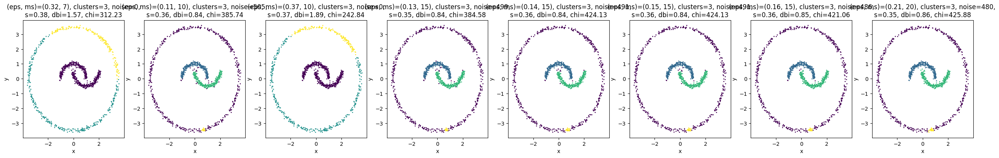

In [21]:
epses = np.arange(0.10, 0.4, .01)
mses = [3, 5, 7, 10, 15, 20]

models = {(eps, ms): DBSCAN(eps=eps, min_samples=ms).fit(X) for ms in mses for eps in epses}

labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, models.keys(), key_name='(eps, ms)', plot_keys=[])

# Pick only where three clusters are identified
keys = [key for key in models if clusters[key] == 3]
print(f"Number of combinations for clusters == 3: {len(keys)}")

plot_dbscan(X, models, keys, clusters, noises, silhouettes, dbi, chi, key_name='(eps, ms)')

### 2.3.2. <a id='toc2_3_2_'></a>[DBSCAN Failure](#toc0_)
DBSCAN is not able identify the three clusters without large noise. DBSCAN relies on a single global density threshold. So, if within-cluster gap in outer ring is comparable to the gap in the two semi-circle separation, we get disjointed clusters and noise. Several combination of `eps` and `min_samples` are not able to correctly separate inner semi-circle without spoiling the outer circle. This is a fundamental limitation of the uniform-density of DBSCAN for this structure.

## 2.4. <a id='toc2_4_'></a>[HDBSCAN (Can Adaptive Density Help?)](#toc0_)
Since DBSCAN's single `eps` failed, we shall try HDBSCAN, which extracts clusters across multiple density levels. HDBSCAN builds a hierarchy of density-connected components and selects the most persistent ones, without committing to a single threshold. The main hyperparameter is `min_cluster_size`, which specifies the minimum number of points required to form a cluster. Smaller values allow finer clusters to be detected, while larger values produce fewer, more stable clusters.


,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,5.45,28.22,0.05,1
1,10,3,5.45,28.22,0.05,1
2,20,3,5.45,28.22,0.05,1
3,50,3,5.45,28.22,0.05,1
4,100,3,5.45,28.22,0.05,1


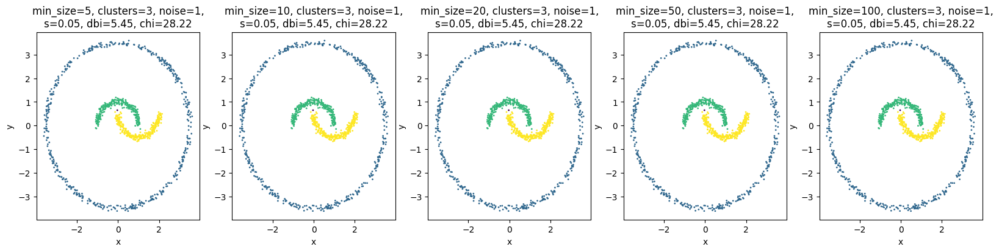

In [22]:
sizes = [5, 10, 20, 50, 100]

hdbs = {size: HDBSCAN(min_cluster_size=size, min_samples=5).fit(X) for size in sizes}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, hdbs, sizes, 'min_size')

HDBSCAN successfully identifies three clusters visually as well. Moreover it does this for various `min_cluster_size` (tested between 5 and 100). Hence the result are visually correct and **stable**

Unlike DBSCAN, HDBSCAN builds a hierarchy of density-based clusters and selects the most stable cluster structure. Although the outer ring contains considerable gaps between individual points, these are consistent with the overall density of the ring and remain connected across multiple density levels. On the other hand, the separation between the two semi-circles forms a more persistent density boundary. By considering cluster stability over a range of density thresholds, HDBSCAN is able to correctly distinguish the three clusters.

## 2.5. <a id='toc2_5_'></a>[OPTICS](#toc0_)

OPTICS is density-based but doesn't require fixed `eps` like DBSCAN. Instead, it orders points based on their density reachability and reveals clustering structure at multiple levels.

,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,82,0.51,7936.18,0.57,399
1,10,33,0.42,4337.58,0.65,522
2,20,13,0.56,1227.99,0.48,242
3,50,5,0.43,1239.22,0.58,519
4,100,1,NaN,NaN,NaN,499


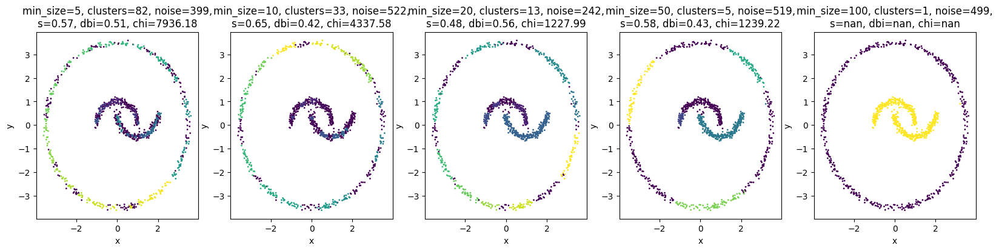

In [23]:
sizes = [5, 10, 20, 50, 100]

optics = {size: OPTICS(min_samples=size).fit(X) for size in sizes}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, optics, sizes, 'min_size')

Neither two nor three clusters are identified. Need more work to identify the causes. Instead try other models.

## 2.6. <a id='toc2_6_'></a>[Spectral Clustering](#toc0_)
Spectral Clustering is a graph-based clustering algorithm that groups points based on their connectivity rather than distance to a cluster centre. This makes it suitable for non-convex shapes.

The main hyperparameter is `n_clusters`. Another important hyperparameter is `affinity`, which determines how similarities between points are calculated. We can choose between `rbf` which uses a gaussian similarity function 

$$
s(x_i, x_j) = e^{-\gamma \|x_i - x_j\|^2}
$$

where `gamma` controls how quickly similarity decreases with distance, and `nearest_neighbors` which connects each point to it's nearest `n_neighbors`. Intuitively, `nearest_neighbors` seems to be more appropriate for a sparsely connected graph in a ring and semi-circle. `rbf` is more appropriate for convex, dense clusters.

Additionally we will use default value for `assign_labels=kmeans`. This uses K-means algorithm to assign labels.

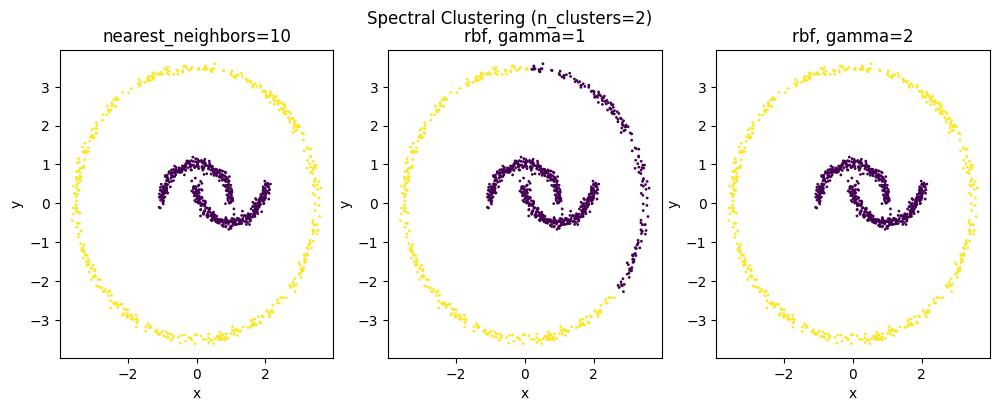

In [24]:
n_clusters = 2
n_neighbors = 5

configs = [
    {'affinity': 'nearest_neighbors'},
    {'affinity': 'rbf', 'gamma': 1},
    {'affinity': 'rbf', 'gamma': 2},
]

sc_labels_all = plot_spectral_clustering(X, n_clusters, RANDOM_STATE, configs)

Spectral Clustering is able to identify two clusters with `nearest_neighbors` affinity. For `rbf`, higher `gamma` places greater emphasis on the nearby points, resulting in more local similarity graph. This is similar to low value of `n_neighbors` with `nearest_neghbors` affinity, as observed. Let's look at 3-clusters more closely

### 2.6.1. <a id='toc2_6_1_'></a>[Three-clusters](#toc0_)
With `n_clusters=3` and `affinity=nearest_neighbors`, we try to vary `n_neighbors` to control how local the affinity graph is.

,neighbours,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,0.64,13.77,0.00,0
1,10,3,4.79,33.71,0.10,0
2,15,3,5.56,34.37,0.10,0
3,20,3,5.45,33.22,0.09,0
4,25,3,5.39,31.66,0.08,0
5,27,3,5.41,28.81,0.06,0
6,50,3,5.41,28.71,0.06,0


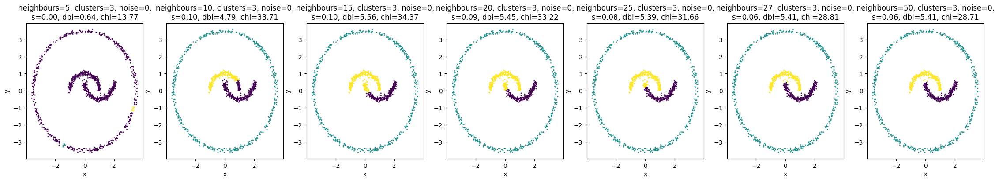

In [25]:
n_clusters = 3
aff = 'nearest_neighbors'
neighbours = [5, 10, 15, 20, 25, 27, 50]

models = {n: SpectralClustering(n_clusters=n_clusters, affinity=aff, n_neighbors=n, random_state=RANDOM_STATE).fit(X) for n in neighbours}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, models.keys(), 'neighbours')

Stability is achieved at `n_neighbors=27`

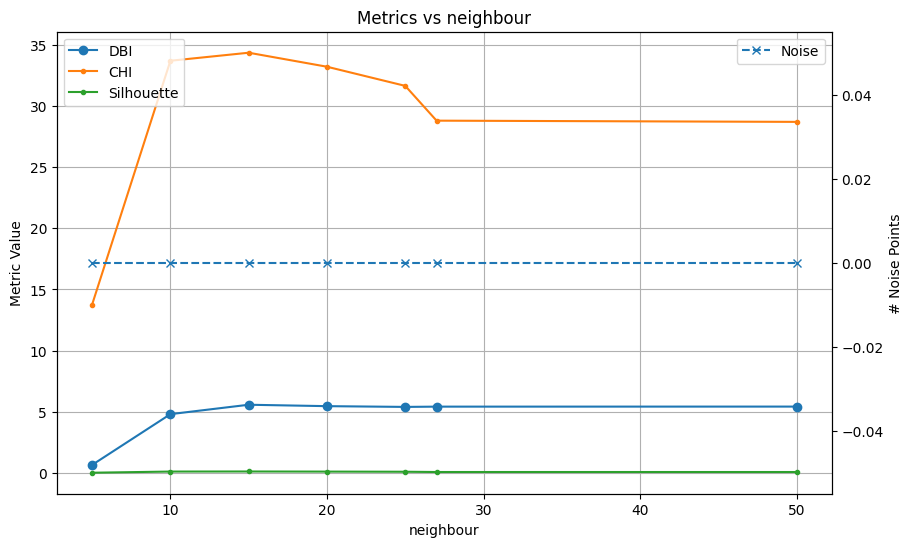

In [26]:
plot_dbscan_metrics(neighbours, dbi, chi, silhouettes, noises, 'neighbour')

Spectral clustering is able to successfully separate each semi-circles and the outer ring. A larger `n_neighbours` builds an affinity graph that captures the global ring cluster while still respecting the gap between semi-circles. Smaller value fragments the ring or misidentify the gap.

## 2.7. <a id='toc2_7_'></a>[Gaussian Mixture Models (GMM)](#toc0_)
GMM is a probabilistic method that assumes data is generated from a mixture of several Gaussian distributions. Like K-Means, GMM needs `n_components` for number of clusters. It picks `init_params=kmeans` to initialize the means.

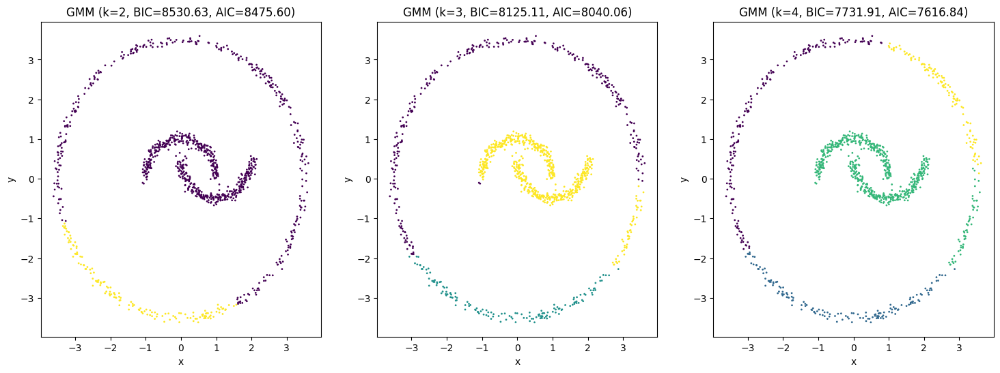

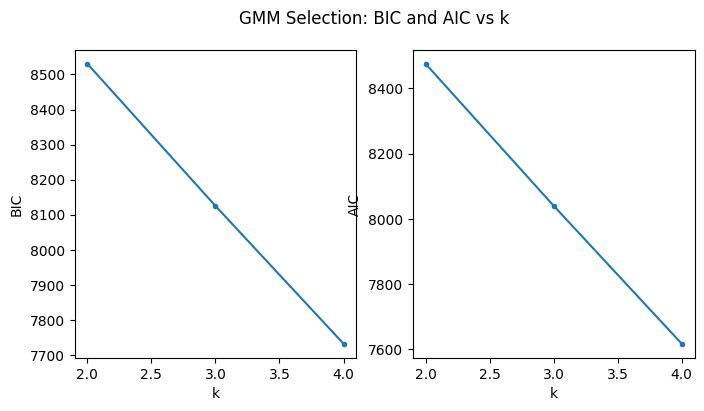

Best AIC score for k=4, score=7616.84
Best BIC score for k=4, score=7731.91


In [27]:
# Fit all GMM once
ks = range(2, 5)

gmms = {k: GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit(X) for k in ks}
labels, aics, bics, scores = get_plot_gmm_metrics(X, gmms)

Ring and semi-circles don't follow Gaussian distribution, so expectedly GMM fails to represent with different Gaussian components.

## 2.8. <a id='toc2_8_'></a>[Agglomerative](#toc0_)
Agglomerative clustering groups points into clusters based on their proximity. It is a type of hierarchical clustering that follows bottom-up approach. Given HDBSCAN worked reasonably well for `n_clusters=3`, let's see if agglomerative clustering can work too. Further, Agglomerative hyperparamter `linkage` can be changed.

,linkage,Clusters,DBI,CHI,Silhouette,Noise
0,single,3,1.65,279.09,0.36,0
1,complete,3,1.13,481.34,0.41,0
2,average,3,0.83,504.13,0.42,0
3,ward,3,0.79,558.72,0.44,0


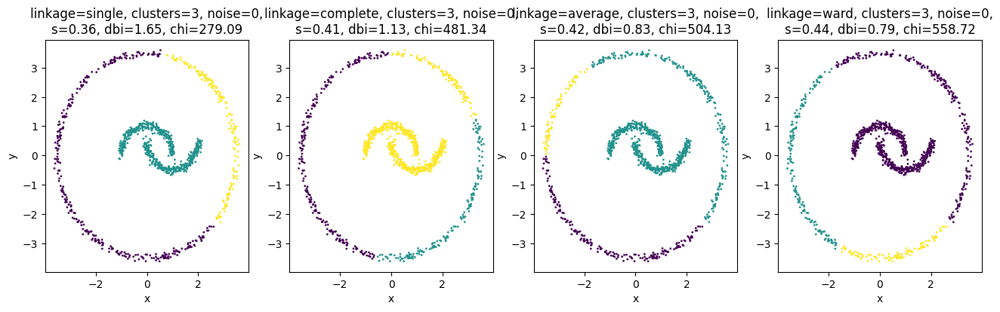

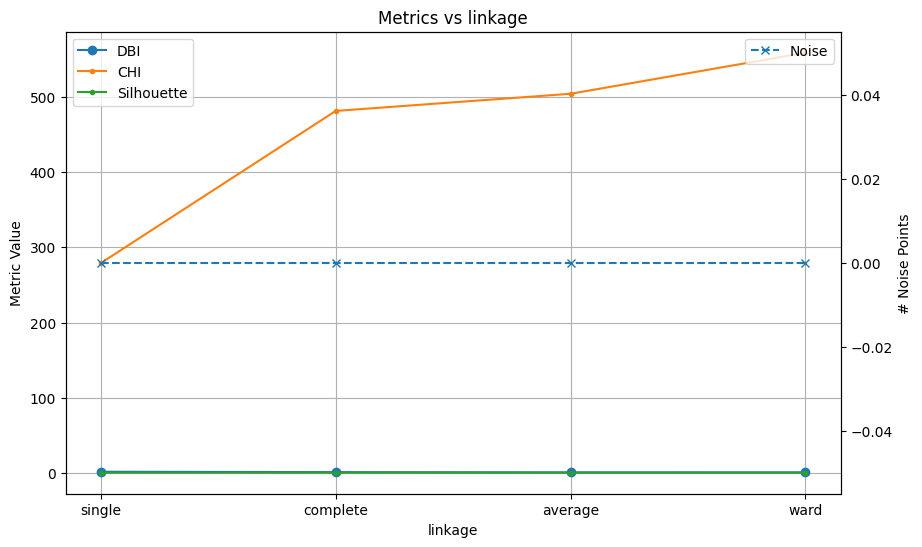

In [28]:
k = 3
linkages = ['single', 'complete', 'average', 'ward']
models = {link: AgglomerativeClustering(n_clusters=k, linkage=link).fit(X) for link in linkages}

labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, keys=models.keys(), key_name='linkage')

plot_dbscan_metrics(linkages, dbi, chi, silhouettes, noises, 'linkage')

No linkage method produces the correct three-cluster separation.
- **Single** splits the ring while merging semi-circles because the gap between the semi-circles is smaller than some gaps within the ring.
- **Complete** clusters are similar to K-Means as it penalizes large within-cluster distances, which rings inherently have - hence splitting in the ring.
- **Average** is a compromise between the two but still doesn't work as required.
- **Ward** minimizes within-cluster variance making compact clusters like K-Means, hence splitting the ring.

### 2.8.1. <a id='toc2_8_1_'></a>[Why HDBSCAN works but Agglomerative fails?](#toc0_)
HDBSCAN improves on single-linkage clustering by considering both distance and local density. This makes it more robust to noise and better at finding clusters with irregular shapes.

On the other hand, Agglomerative clustering relies directly on pairwise distances and does not account for density structure. As a result, it cannot distinguish between small yet meaningful structural gaps (inter-cluster between the semi-circles) and larger yet inconsequential gaps due to geometry (within-cluster in ring), leading to incorrect merging or splitting of clusters.

## 2.9. <a id='toc2_9_'></a>[Conclusion](#toc0_)
Dataset 1 contains non-convex ring and semi-circles. Overall, this dataset demonstrates that dataset geometry is often more important than raw metric scores when selecting a clustering algorithm.

| Model | Assessment | Verdict |
|---------|---------|---------|
| K-Means | Fast baseline but works poorly because of convex assumption do not match dataset's geometry | Rejected |
| GMM | Works poorly becasue constrained by Gaussian assumption | Rejected |
| DBSCAN | Successfully recovered non-convex structures but fails at variable density and overestimates noise | Rejected |
| Spectral | Successfully recovered non-convex structures as graph-based approach aligned with geometry | Strong |
| HDBSCAN | Produced stable density-based clusters and handled noise robustly | Preferred |
| OPTICS | Density reachability ordering doesn't work  | Rejected |
| Agglomerative | All linkage methods fail to clearly capture both density and distance based linkage  | Rejected |

**Preferred** HDBSCAN (with Spectral as a more expensive close alternative).

Internal validation metrics alone do not fully capture clustering quality here. Visual inspection and cluster geometry indicate that HDBSCAN provides the most meaningful segmentation.

# 3. <a id='toc3_'></a>[Dataset 2](#toc0_)

## 3.1. <a id='toc3_1_'></a>[Exploration](#toc0_)

In [29]:
df2.describe()

,x,y,z
count,1200.000000,1200.000000,1200.000000
mean,1.087790,0.770076,0.722831
std,2.473760,2.985778,1.940448
min,-8.169034,-9.237507,-6.787154
25%,0.122513,-1.205877,-0.223841
50%,1.002080,0.791666,0.141612
75%,2.202543,2.791470,0.778096
max,9.502112,9.716520,9.526249


Shape: (1200, 3), x: (-8.17, 9.50), y: (-9.24, 9.72), z: (-6.79, 9.53)


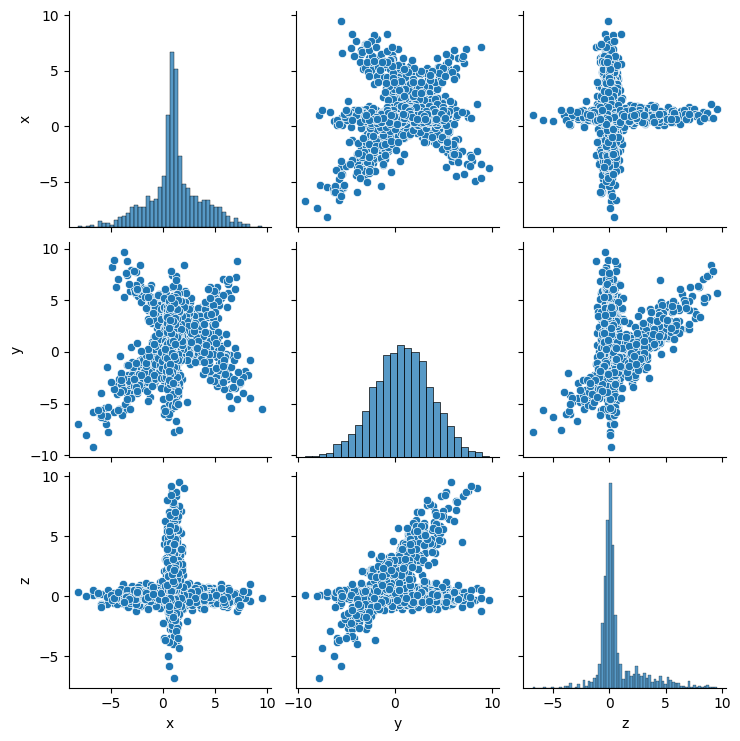

In [30]:
X = df2[['x', 'y', 'z']].to_numpy()
print(f"Shape: {X.shape}, x: ({X[:, 0].min():.2f}, {X[:, 0].max():.2f}), y: ({X[:, 1].min():.2f}, {X[:, 1].max():.2f}), z: ({X[:, 2].min():.2f}, {X[:, 2].max():.2f})")

fig = px.scatter_3d(df2, x='x', y='y', z='z', width=800, height=600)
fig.update_traces(marker_size=3)
fig.show()

sns.pairplot(df2)
plt.show()

Shape: (1200, 3), x: (-8.17, 9.50), y: (-9.24, 9.72)


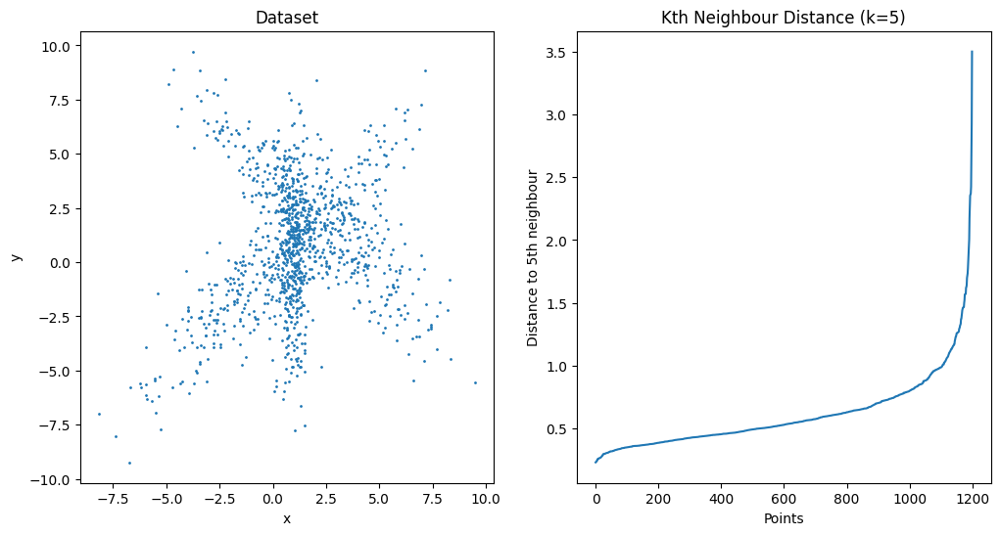

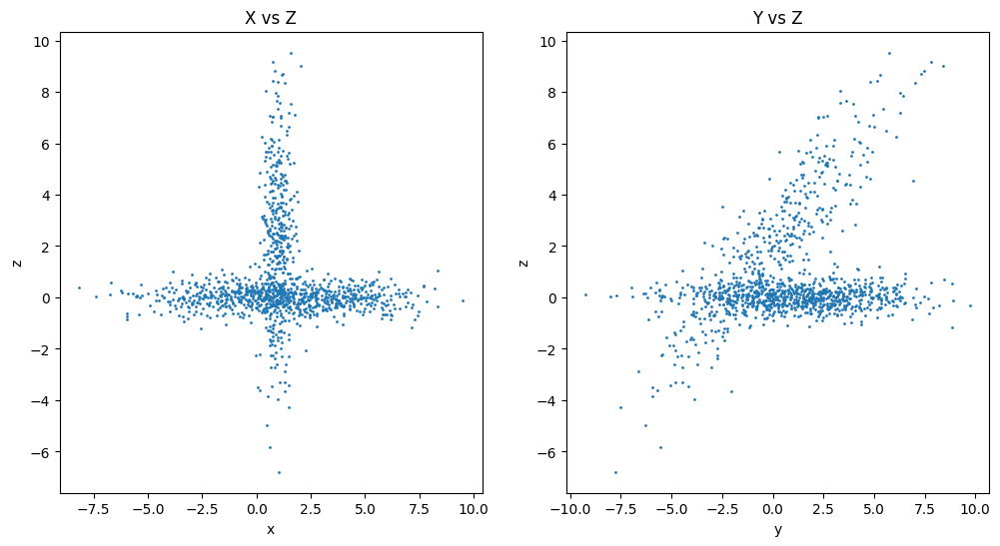

In [31]:
explore_2d(X)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].scatter(X[:, 0], X[:, 2], s=1)
axs[0].set_title("X vs Z")
axs[0].set_xlabel('x')
axs[0].set_ylabel('z')

axs[1].scatter(X[:, 1], X[:, 2], s=1)
axs[1].set_title("Y vs Z")
axs[1].set_xlabel('y')
axs[1].set_ylabel('z')

plt.show()

Kth nearest neighbour for `k=5` has abrupt change between 0.6 to 1.5

### 3.1.1. <a id='toc3_1_1_'></a>[Dimensionality Reduction](#toc0_)
For 3D, let's first check whether all three carry meaningful variance. We can remove less meaningful feature and reduce dimensions, which is simpler.

Use PCA to decompose the dataset variance across the principal axes. Boruta is not used as it is supervised method and we don't have target. Similarly SHAP is not going to be helpful for feature explainability.

In [32]:
pca = PCA(n_components=3).fit(X)
print(f"PCA variance breakdown: {pca.explained_variance_ratio_}")

PCA variance breakdown: [0.52327786 0.3121292  0.16459294]


PCA shows that all three principal components carry meaningful variance (52%, 31%, 16%). Let's use t-SNE to project in 2D by maintaining local neighbourhood structure. t-SNE takes `perplexity` parameter to balance local v. global neighbourhood information.

Shape: (1200, 2), x: (-43.43, 41.42), y: (-47.65, 42.96)


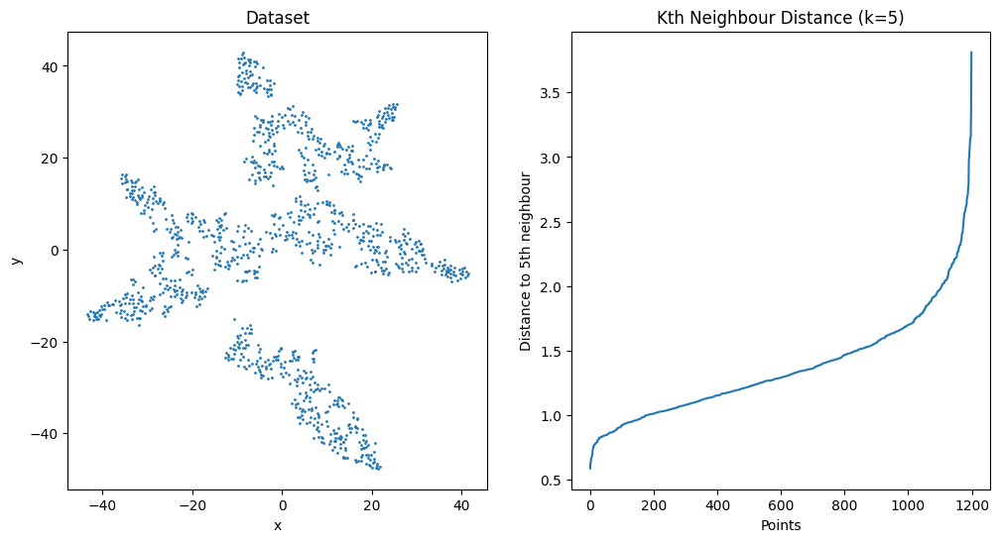

Shape: (1200, 2), x: (-19.18, 17.99), y: (-21.65, 19.16)


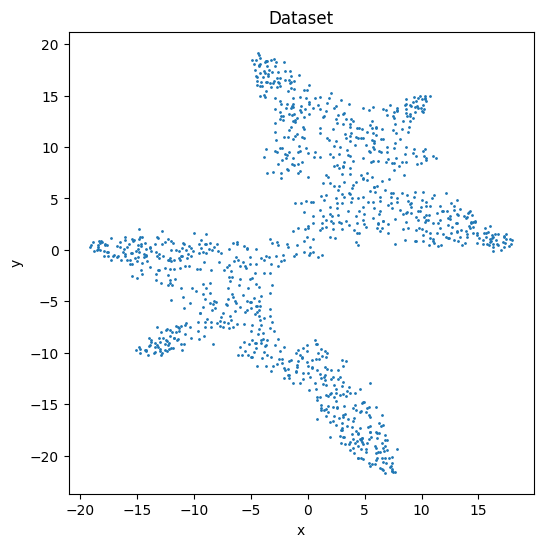

In [33]:
tsne = TSNE(random_state=RANDOM_STATE).fit_transform(X)
explore_2d(tsne)

tsne = TSNE(perplexity=100, random_state=RANDOM_STATE).fit_transform(X)
explore_2d(tsne, k=0)

t-SNE shows similar structures with `perplexity` 30 and 100, which suggests neighbourhood relationships are stable and well-defined. The neighbourhood structure confirms what we see in the 3D plot - there are chain of points with overlapping neighbourhoods - grouped as the continuous bridge.

### 3.1.2. <a id='toc3_1_2_'></a>[Observations](#toc0_)
- No need to normalize since `x`, `y`, `z` are on similar scale.
- No missing or apparent anomalous data points.
- Dimensionality reduction may not work as all three principal components contribute meaningful variance. 
- Data seems three intertwined elongated arms. In the absence of ground-truth, we can assume that the clusters should follow the same shapes, **three clusters**.
- Alternatively, some convex and density based models may identify the continuous bridge as one cluster and the elongated arms as six more clusters.
- In either scenario, each arm seems to follow gaussian distribution - denser at the center and sparser at the edges.
- Kth neighbour distance shows elbow from 0.6 to 1.2.

### 3.1.3. <a id='toc3_1_3_'></a>[Algorithm Strategy](#toc0_)
- **K-Means**: Baseline, not convex so shall perform poorly.
- **GMM**: Great candidate to check if it can stretch gaussian components along the arms.
- **DBSCAN**/**HDBSCAN**: Not good candidates as the overlapping arms may confuse.
- **Spectral**: Check if graph connectivity can capture arms across the bridge.

## 3.2. <a id='toc3_2_'></a>[K-Means](#toc0_)

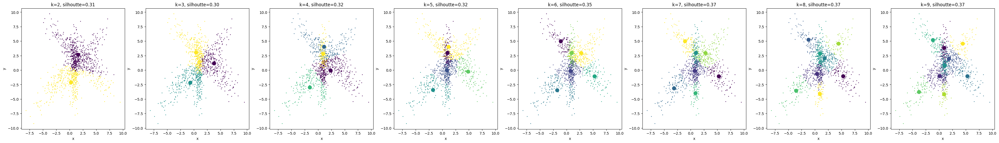

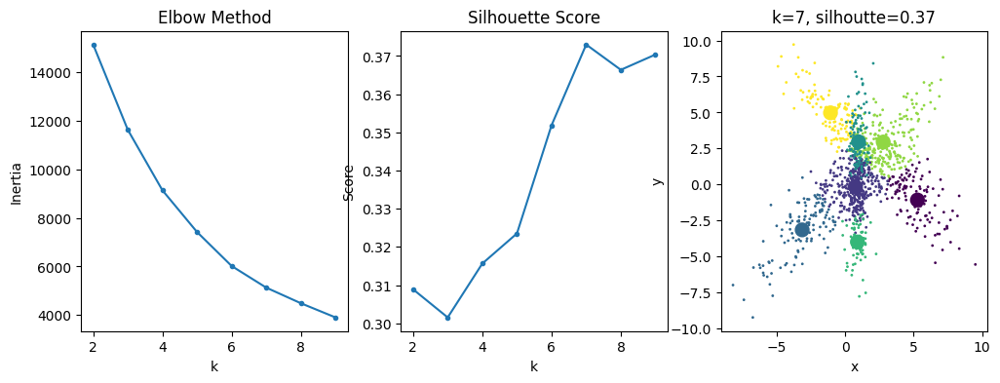

Highest silhouette score for k=7


In [34]:
ks = range(2, 10)
kms, labels, inertias, silhouettes = get_kmeans_metrics(X, ks)

find_plot_best_k(ks, X, kms, inertias, silhouettes)

In [35]:
k = max(silhouettes, key=silhouettes.get)
df2["label"] = kms[k].labels_

fig = px.scatter_3d(df2, x='x', y='y', z='z', title=f'k={k}', color='label', width=800, height=600)
fig.update_traces(marker_size=3)
fig.show()

kmeans_k = k
kmeans_labels = kms[k].labels_

As expected K-Means doesn't identify the three elongated arms. Instead it identifies the bridge as a cluster, and the six ends of the three arms as six clusters. This is expected behaviour from distance-based models as discussed earlier.

### 3.2.1. <a id='toc3_2_1_'></a>[K-Means on Top Two Components by PCA](#toc0_)
Let's compare K-Means on two principal components with 3D. Since third principal component carries 16% variance, removing it is expected to perform poorly in comparison.

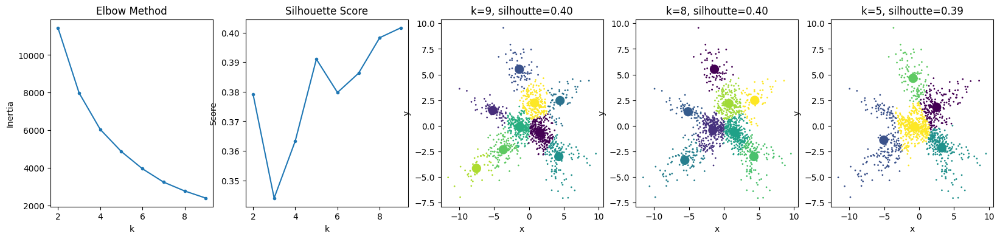

Highest silhouette score for k=9


In [36]:
ks = range(2, 10)

X_pca = PCA(n_components=2).fit_transform(X)
kms, labels, inertias, silhouettes = get_kmeans_metrics(X_pca, ks, plot_ks=[])

find_plot_best_k(ks, X_pca, kms, inertias, silhouettes, 3)

In [37]:
k = max(silhouettes, key=silhouettes.get)
df2["label"] = kms[k].labels_

fig = px.scatter_3d(df2, x='x', y='y', z='z', title=f'k={k}', color='label', width=800, height=600)
fig.update_traces(marker_size=3)
fig.show()

As expected from the PCA analysis before, reducing to 2D degrades performance by reducing silhouette scores, in addition to changing clustering structure.

## 3.3. <a id='toc3_3_'></a>[Gaussian Mixture Models (GMM)](#toc0_)
Given the data has elongated arms with seemingly Gaussian distribution, GMM is a good candidate. We can apply GMM with `covariance=full` such that each Gaussian component has its own covariance matrix and can stretch along the arm direction.

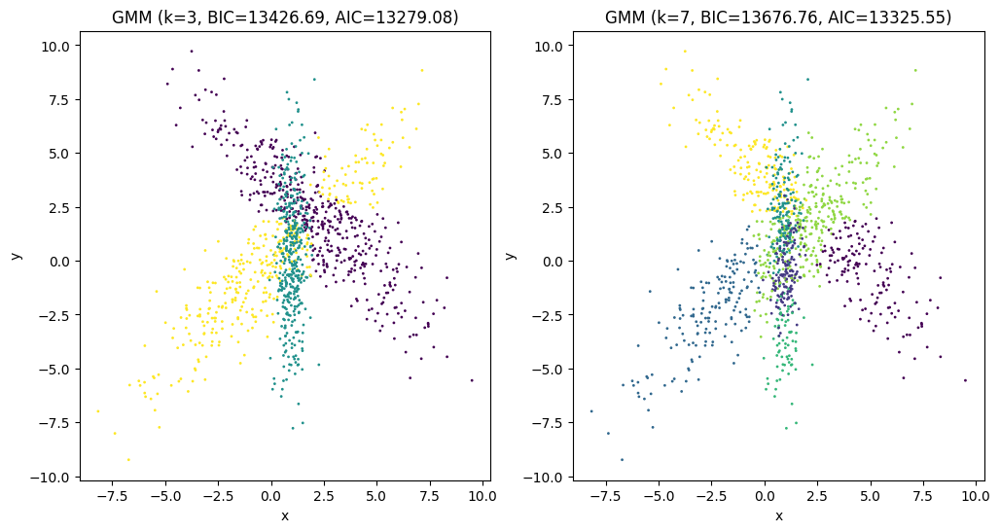

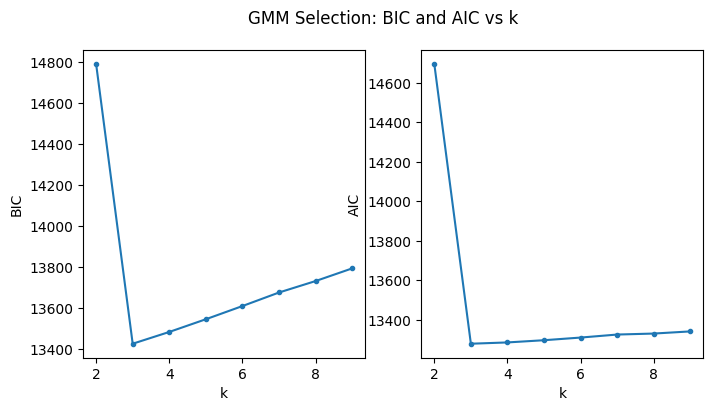

Best AIC score for k=3, score=13279.08
Best BIC score for k=3, score=13426.69


In [38]:
ks = range(2, 10)

gmms = {k: GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit(X) for k in ks}
labels, aics, bics, scores = get_plot_gmm_metrics(X, gmms, plot_ks=[3, 7])


### 3.3.1. <a id='toc3_3_1_'></a>[Best Model Selection](#toc0_)
In GMM, increasing the number of components improves likelihood, so we need to penalize increased complexity. Unlike K-Means, GMM is probabilistic model so Elbow method may not work. Hence, we use statistical methods based on likelihood - AIC and BIC - to compare different models. Both AIC and BIC are optimized for `k=3` which is the expected result

In [39]:
k = 3

df2["label"] = labels[k]

fig = px.scatter_3d(df2, x='x', y='y', z='z', title=f'k={k}', color='label', width=800, height=600)
fig.update_traces(marker_size=3)
fig.show()

gmm_k = k
gmm_labels = labels[k]

GMM is able to separate the arms in separate clusters fairly well. The central overlapping bridge is getting clustered based on initialization state.

### 3.3.2. <a id='toc3_3_2_'></a>[Random Initialization](#toc0_)
GMM uses EM algorithm, which starts from a given initialization of parameters. Hence, the final clustering result can depend on initialization state. Earlier we used K-Means to initialize the state. Now, let's try different `random_state` and compare log-likelihood score and similarity between cluster results by considering all pairs of samples.

If the model is stable, we expect similar results across different seeds. If it is unstable, different seeds will lead to different cluster structures and scores.

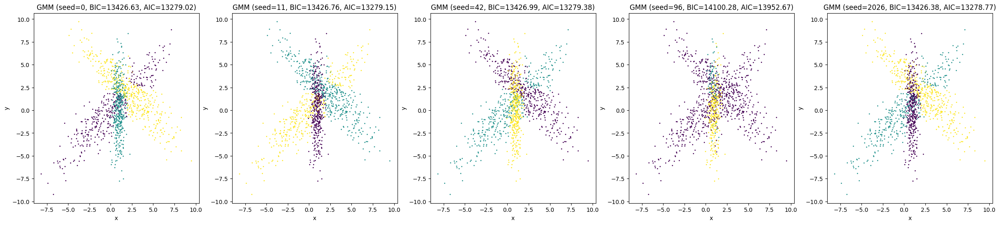

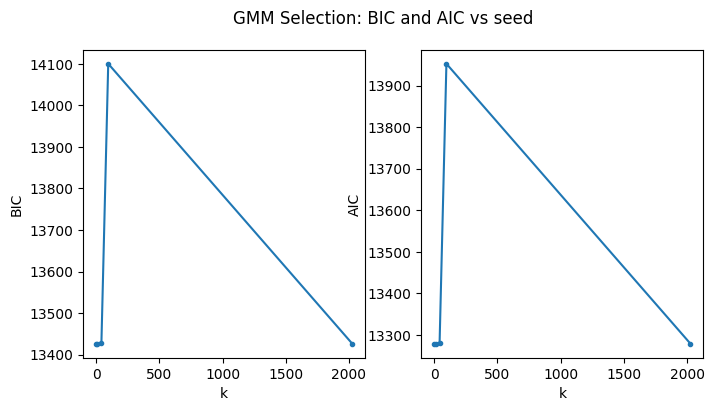

Best AIC score for k=2026, score=13278.77
Best BIC score for k=2026, score=13426.38

Cluster stability (ARI between clusters):


,0,11,42,96,2026
0,1.00,1.00,0.94,0.42,0.98
11,1.00,1.00,0.94,0.42,0.97
42,0.94,0.94,1.00,0.42,0.97
96,0.42,0.42,0.42,1.00,0.42
2026,0.98,0.97,0.97,0.42,1.00


In [40]:
seeds = [0, 11, RANDOM_STATE, 96, 2026]

gmms = {seed: GaussianMixture(n_components=k, random_state=seed, init_params='random').fit(X) for seed in seeds}

labels, aics, bics, scores = get_plot_gmm_metrics(X, gmms, 'seed')

print("\nCluster stability (ARI between clusters):")
ari = np.array([[adjusted_rand_score(labels[i], labels[j]) for j in seeds] for i in seeds])
df = pd.DataFrame(ari, index=seeds, columns=seeds)

df.style.map(lambda v: "background-color: pink" if v < 0.9 else "").format("{:.2f}")

In [41]:
seed = 96

df2["label"] = labels[seed]

fig = px.scatter_3d(df2, x='x', y='y', z='z', title=f'seed={seed}', color='label', width=800, height=600)
fig.update_traces(marker_size=3)
fig.show()

gmm_labels_2 = labels[seed]

This configuration does not look meaningful, which suggests we need to be careful when using GMM, since the result can depend on which local optimum the algorithm converges to.

### 3.3.3. <a id='toc3_3_3_'></a>[GMM Stability](#toc0_)
The results show that most seeds produce highly consistent clustering structures, with ARI close to 1.0, indicating that the model is mostly stable and converges to the same solution even with different initializations. One seed (96), however, produced considerably different result (ARI=0.4), suggesting presence of multiple local optima in the likelihood surface.

Overall, the clustering is mostly stable, though not completely unique (depending on how the model is initialized).

## 3.4. <a id='toc3_4_'></a>[DBSCAN](#toc0_)
Let's try DBSCAN with the `eps` based on kth nearest neighbour distance for `k=5` and `min_samples=5`.

,eps,Clusters,DBI,CHI,Silhouette,Noise
0,0.60,10,0.68,40.84,-0.10,263
1,0.80,4,0.50,34.09,0.18,108
2,0.90,3,0.53,53.82,0.28,70
3,1.00,3,0.43,57.50,0.38,49
4,1.10,2,0.50,16.28,0.38,33
5,1.15,2,0.50,16.14,0.38,29
6,1.20,1,NaN,NaN,NaN,27
7,2.00,1,NaN,NaN,NaN,5


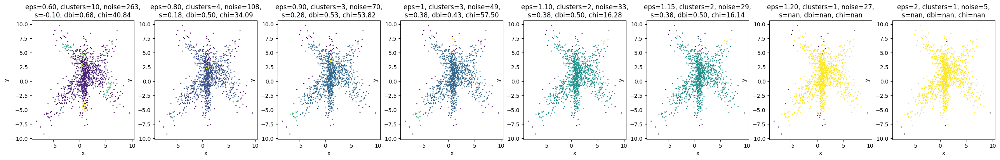

In [42]:
epses = [0.6, 0.8, 0.9, 1, 1.1, 1.15, 1.2, 2]

dbs = {eps: DBSCAN(eps=eps, min_samples=5).fit(X) for eps in epses}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, dbs, epses)

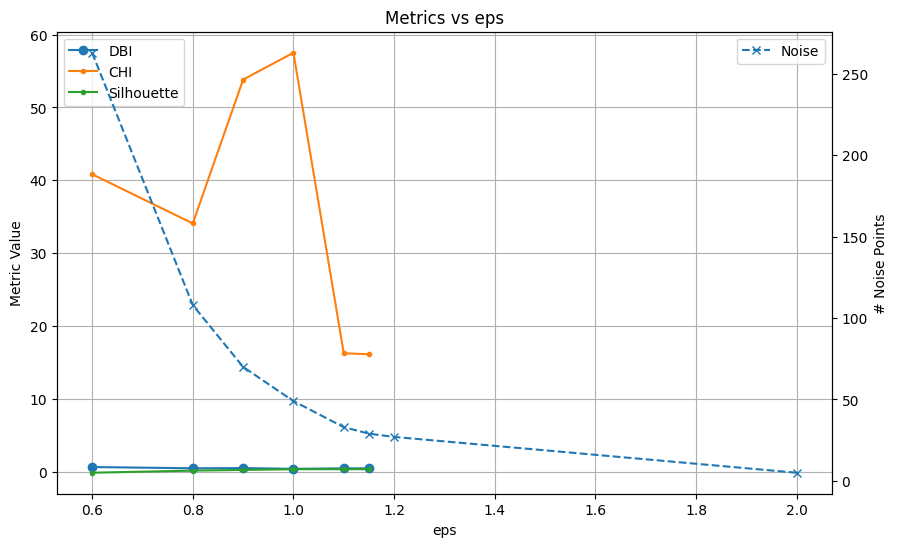

In [43]:
plot_dbscan_metrics(epses, dbi, chi, silhouettes, noises, 'eps')

As expected, DBSCAN's density based algorithm doesn't work well to identify the elongated arms correctly. In fact, it performs poorer than K-Means in that it is not able to separate ends of the elongated arms as well.

In [44]:
eps_list = [0.6, 1, 1.15]

fig = make_subplots(1, len(eps_list), specs=[[{'type':'scene'}] * len(eps_list)], subplot_titles=[f'eps={eps}, clusters={clusters[eps]}' for eps in eps_list])

for i, key in enumerate(eps_list):
    df2["label"] = labels[key]

    sub_fig = px.scatter_3d(df2, x='x', y='y', z='z', color='label')
    for trace in sub_fig.data:
        fig.add_trace(trace, row=1, col=i + 1)
        fig.update_traces(marker_size=2)

fig.show()

dbscan_eps = 1
dbscan_labels = labels[1]

To confirm that DBSCAN is not a good solution, let's try another set of hyperparameter `eps` with `min_samples=10`

,eps,Clusters,DBI,CHI,Silhouette,Noise
0,0.60,4,0.62,116.62,0.25,561
1,0.80,3,0.70,58.98,0.17,205
2,0.90,1,NaN,NaN,NaN,137
3,1.00,1,NaN,NaN,NaN,113
4,1.10,2,0.43,82.98,0.48,63
5,1.15,2,0.43,81.09,0.47,55
6,1.20,1,NaN,NaN,NaN,52
7,2.00,1,NaN,NaN,NaN,7


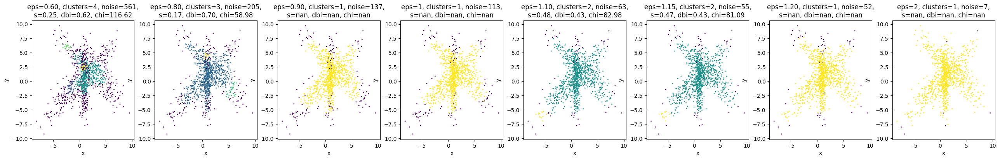

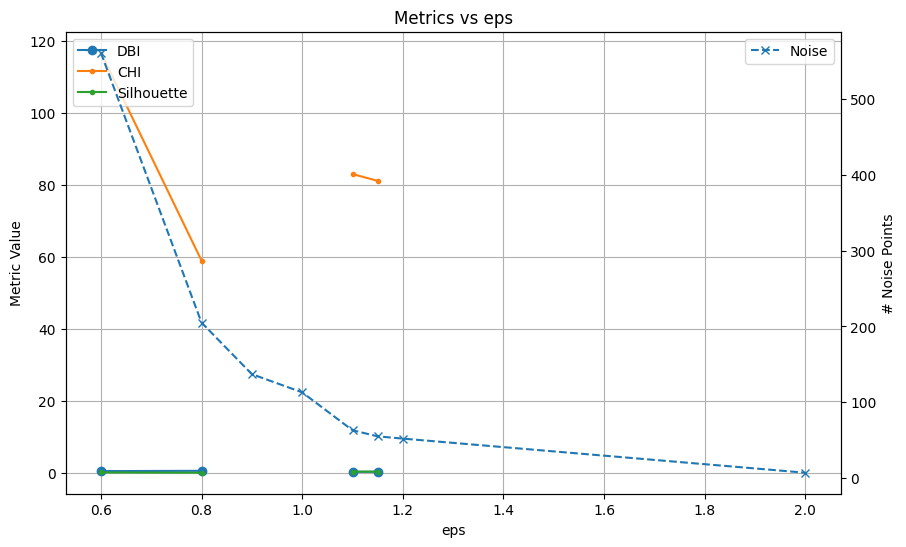

In [45]:
dbs = {eps: DBSCAN(eps=eps, min_samples=10).fit(X) for eps in epses}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, dbs, epses)

plot_dbscan_metrics(epses, dbi, chi, silhouettes, noises, 'eps')

Still poor results because the overalapping bridge is the constraint here, rather than density. Let's try other methods.

## 3.5. <a id='toc3_5_'></a>[HDBSCAN](#toc0_)
It is expected that HDBSCAN should also not work as the issue with DBSCAN is not about the density but rather the separation of clusters by distribution

,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,0.52,43.72,0.28,137
1,10,2,0.42,62.85,0.48,76
2,20,2,0.70,61.80,0.31,426
3,50,2,1.19,142.57,0.27,647
4,100,2,1.19,142.57,0.27,647


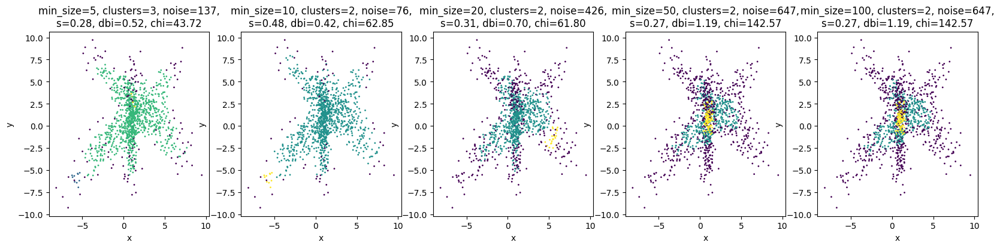

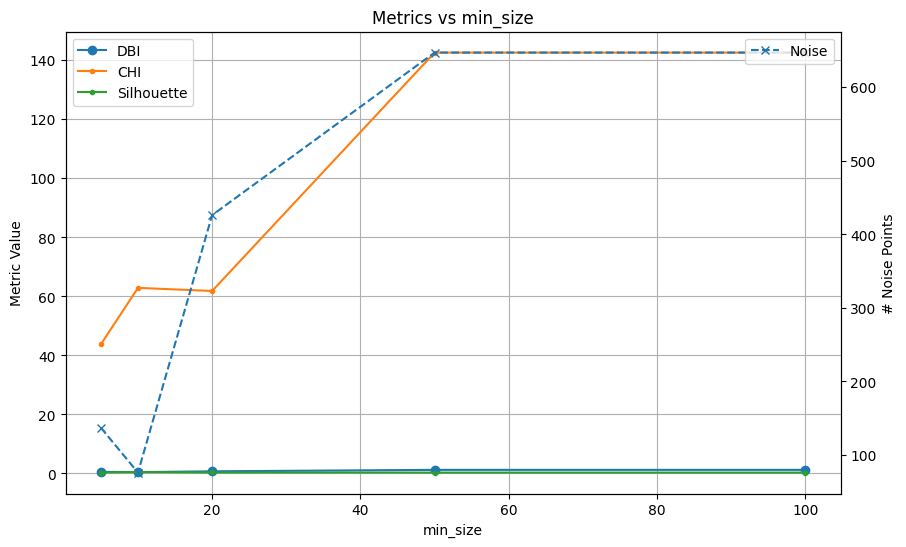

In [46]:
# rename to eps to be able to re-use the same code
# TODO: move this to function call so we can reuse
sizes = [5, 10, 20, 50, 100]

hdbs = {size: HDBSCAN(min_cluster_size=size, min_samples=5).fit(X) for size in sizes}

labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, hdbs, sizes, 'min_size')
plot_dbscan_metrics(sizes, dbi, chi, silhouettes, noises, 'min_size')

As expected, HDBSCAN also fails to correctly identify the arms as clusters.

## 3.6. <a id='toc3_6_'></a>[Spectral Clustering](#toc0_)
Spectral Clustering relies on connectivity, so it is expected to struggle as well. One way to think about it is that if we start connecting points from one end of an arm, the algorithm may continue following the continuous arm but then get confused when it reaches the continuous bridge. Hence, we can expect non-sense or less meaningful clusters for the elongated arms.

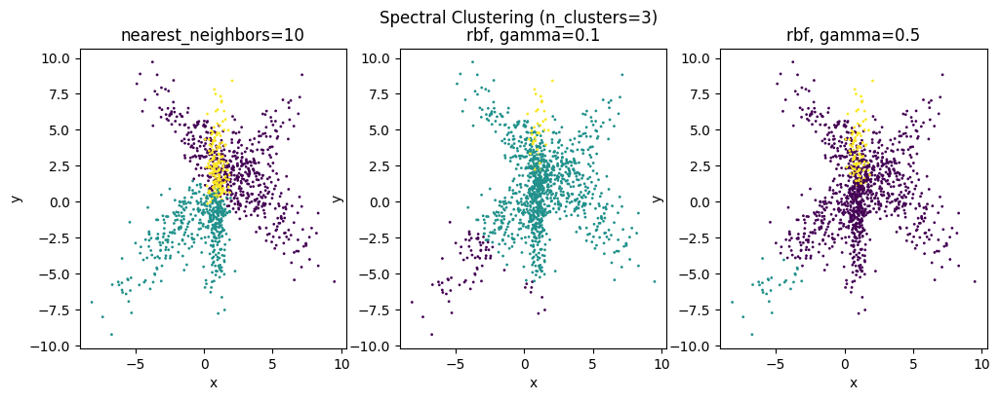

In [47]:
n_clusters = 3
n_neighbors = 5

configs = [
    {"affinity": "nearest_neighbors"},
    {"affinity": "rbf", "gamma": 0.1},
    {"affinity": "rbf", "gamma": 0.5},
]

sc_labels_all = plot_spectral_clustering(X, n_clusters, RANDOM_STATE, configs)

sc_clusters = n_clusters
sc_labels = sc_labels_all[0]

Both `nearest_neighbors` and `rbf` fail to correctly identify the arms for `n_clusters=3`. Also, try for `n_clusters=7` (from K-Means)

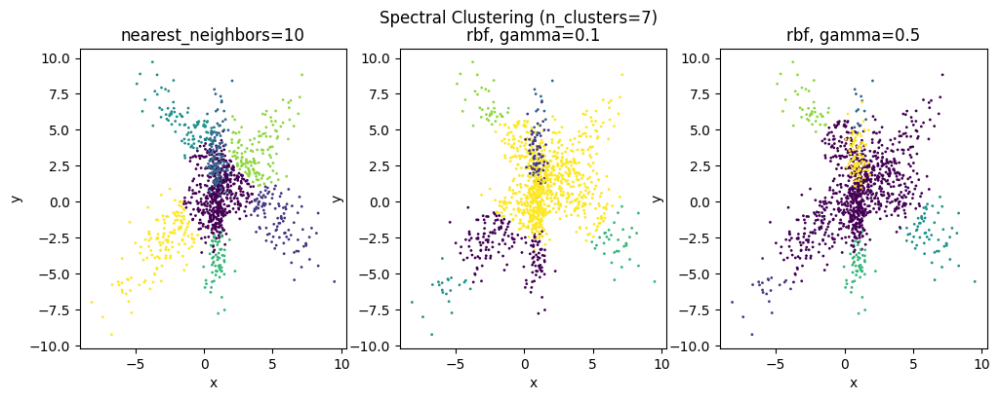

In [48]:
n_clusters = 7
n_neighbors = 5

configs = [
    {"affinity": "nearest_neighbors"},
    {"affinity": "rbf", "gamma": 0.1},
    {"affinity": "rbf", "gamma": 0.5},
]

sc_labels_all = plot_spectral_clustering(X, n_clusters, RANDOM_STATE, configs)

sc_clusters_2 = n_clusters
sc_labels_2 = sc_labels_all[0]

## 3.7. <a id='toc3_7_'></a>[Conclusion](#toc0_)
Dataset 2 contains elongated and overlapping arms that challenge centroid-based clustering. K-Means performed poorly. Density-based methods are also less effective because overlap bridge was challenging rather than density variation. GMM performed most optimum because they can model covariance and best represent gaussian structure of each arm. 

| Model | Assessment | Verdict |
|---------|---------|---------|
| K-Means | Fast baseline but works poorly because convex assumption do not match dataset's geometry | Rejected |
| GMM | Works as can model covariance and best represent gaussian structure of each arm. Results dependent on initialization state | Preferred |
| DBSCAN | Not effective as overlapping bridge is the constraint rather than density | Rejected |
| Spectral | Less effective as graph-based approach also fails at overlapping bridge | Rejected |
| HDBSCAN | Less effective as (variable) density is not the main constraint | Rejected |

OPTICS and Agglomerative are not considered as they are going to suffer same issues as other density and distance based methods.

**Preferred** GMM (most configurations are stable).

The results demonstrate that model assumptions matter more than raw metric values. t-SNE visualisations were useful for qualitative inspection but should not be interpreted as preserving global geometry from the original feature space.

### 3.7.1. <a id='toc3_7_1_'></a>[t-SNE Visualization](#toc0_)

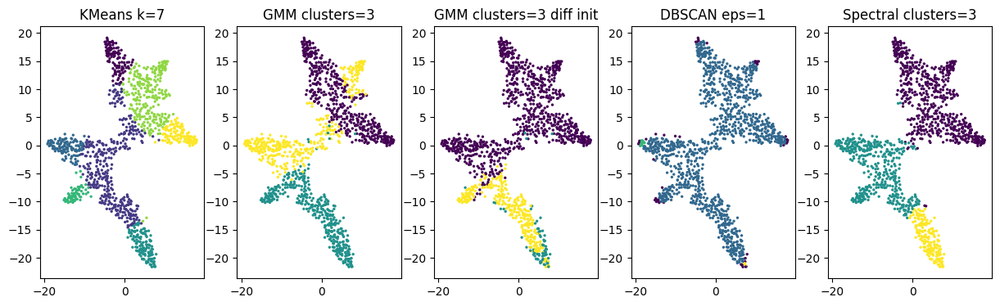

In [49]:
fig, axs = plt.subplots(1, 5, figsize=(15,4))

axs[0].scatter(tsne[:,0], tsne[:,1], c=kmeans_labels, s=2)
axs[0].set_title(f"KMeans k={kmeans_k}")

axs[1].scatter(tsne[:,0], tsne[:,1], c=gmm_labels, s=2)
axs[1].set_title(f"GMM clusters={gmm_k}")

axs[2].scatter(tsne[:,0], tsne[:,1], c=gmm_labels_2, s=2)
axs[2].set_title(f"GMM clusters={gmm_k} diff init")

axs[3].scatter(tsne[:,0], tsne[:,1], c=dbscan_labels, s=2)
axs[3].set_title(f"DBSCAN eps={dbscan_eps}")

axs[4].scatter(tsne[:,0], tsne[:,1], c=sc_labels, s=2)
axs[4].set_title(f"Spectral clusters={sc_clusters}")

plt.show()

The t-SNE visualisations are useful for intuition but to be not treated as proof of cluster quality as global distances are distorted. Across the evaluated methods, probabilistic and graph-based approaches captured the elongated structure better than K-Means. GMM is sensitive to initialization state. The results highlight the importance of matching the clustering model to the underlying geometry rather than relying on a single metric.

# 4. <a id='toc4_'></a>[Dataset 3](#toc0_)

## 4.1. <a id='toc4_1_'></a>[Exploration](#toc0_)

In [50]:
df3.describe()

,x,y
count,2120.000000,2120.000000
mean,0.024495,0.243609
std,4.022428,4.099759
min,-15.361901,-11.608749
25%,-2.499985,-2.101613
50%,0.014368,0.101511
75%,2.472342,2.688312
max,14.090384,11.528489


Shape: (2120, 2), x: (-15.36, 14.09), y: (-11.61, 11.53)


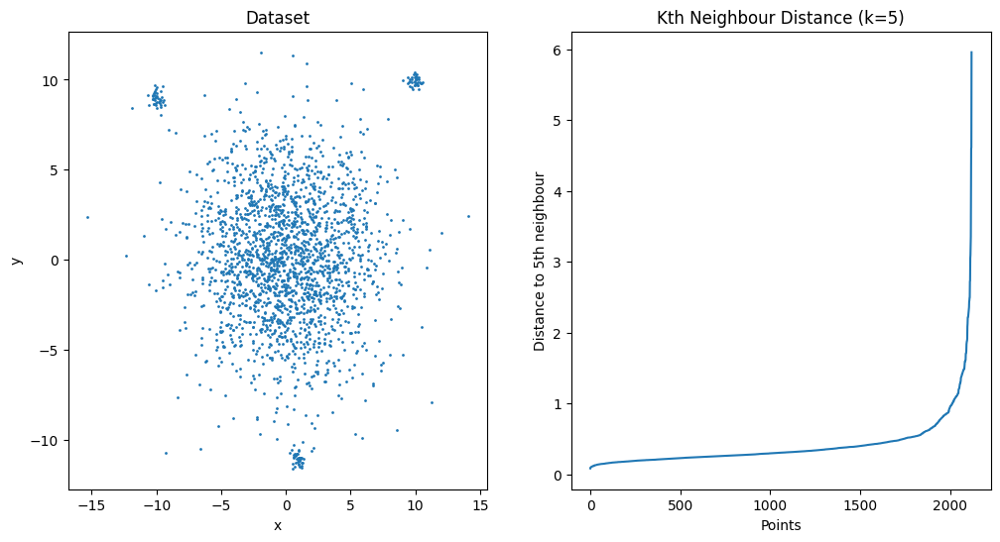

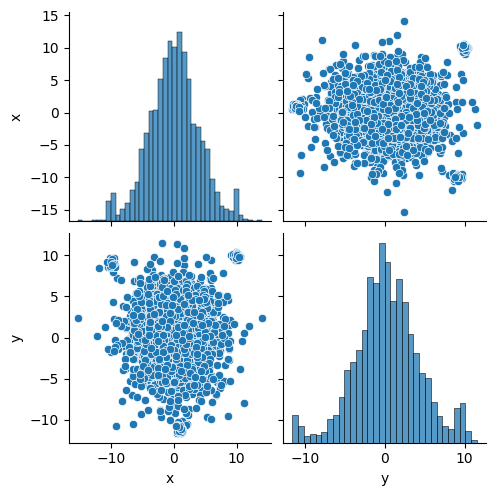

In [51]:
X = df3[['x', 'y']].to_numpy()
explore_2d(X)

sns.pairplot(df3)
plt.show()

### 4.1.1. <a id='toc4_1_1_'></a>[Observations](#toc0_)
- No need to normalize since `x` and `y` are on similar scale.
- No missing or apparent anomalous data points.
- Data seems to be arranged in mostly in a big diffused cloud (seems gaussian), with three separate tiny tight clusters around the cloud. So let's consider **four clusters** (possibly with some noise).
- In the convex space, K-Means could be a good candidate. DBSCAN could have been a good candidate but the density varies in different clusters. Hence, HDBSCAN could be a good choice as it considers multiple density levels.
- Kth neighbour distance for `k=5` changes between 0.5 and 1.5

### 4.1.2. <a id='toc4_1_2_'></a>[Algorithm Strategy](#toc0_)
- **K-Means**: Baseline. seeminly convex space, so could be a good choice.
- **DBSCAN**: Not a good candidate as density varies between clusters.
- **OPTICS**: Good choice for multi-scale density. Reachability plot reveals density hierarchy
- **HDBSCAN**: Good candidate as it handles variable density.
- **Spectral**: Let's see if this works.
- **GMM**: Check if each each cluster be fit in a separate Gaussian

## 4.2. <a id='toc4_2_'></a>[K-Means](#toc0_)

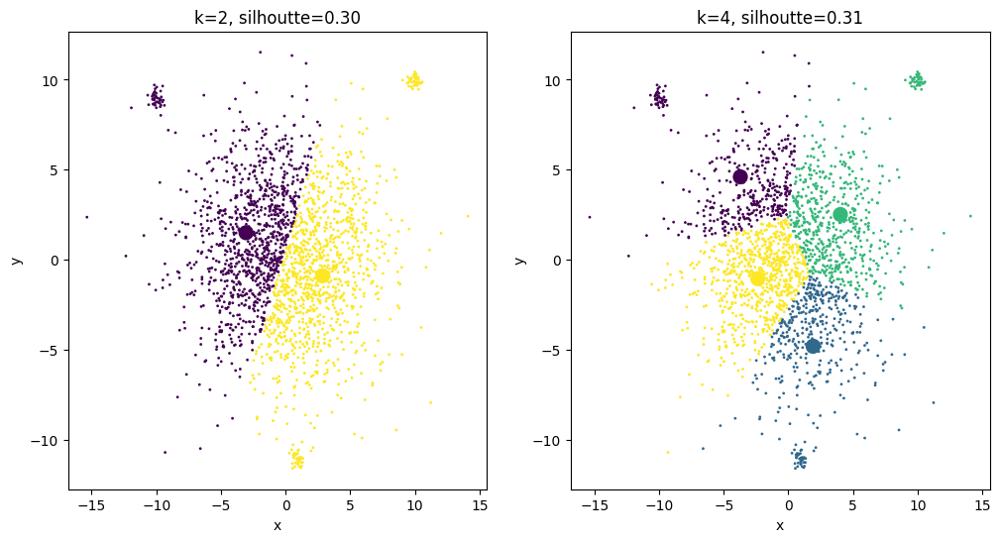

In [52]:
ks = range(2, 10)

kms, labels, inertias, silhouettes = get_kmeans_metrics(X, ks, [2, 4])

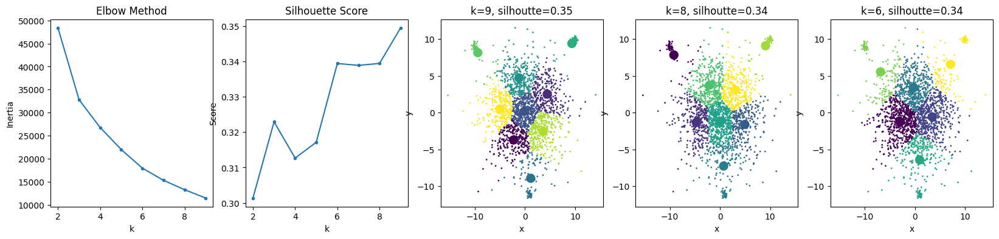

Highest silhouette score for k=9


In [53]:
find_plot_best_k(ks, X, kms, inertias, silhouettes, 3)

K-Means is not able to separate central cloud and peripheral clouds. One possible reason could be the central cluster is too fragmented that separating it into clusters reduces within-cluster distance. We may try noise reduction from DBSCAN.

## 4.3. <a id='toc4_3_'></a>[DBSCAN](#toc0_)

,eps,Clusters,DBI,CHI,Silhouette,Noise
0,0.50,16,0.55,102.37,-0.18,249
1,0.80,10,0.49,134.32,0.04,111
2,1.00,4,0.37,323.07,0.38,64
3,1.10,4,0.38,317.20,0.37,47
4,1.15,3,0.35,317.85,0.47,46
5,1.50,3,0.36,319.09,0.47,28


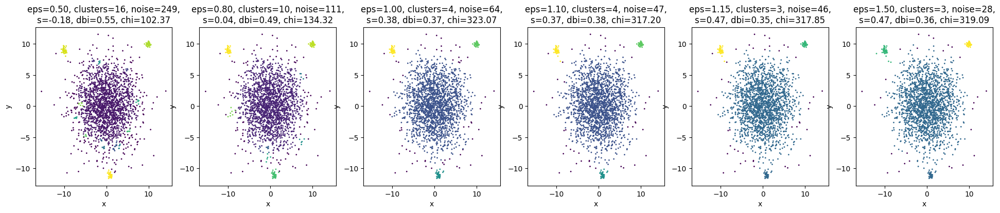

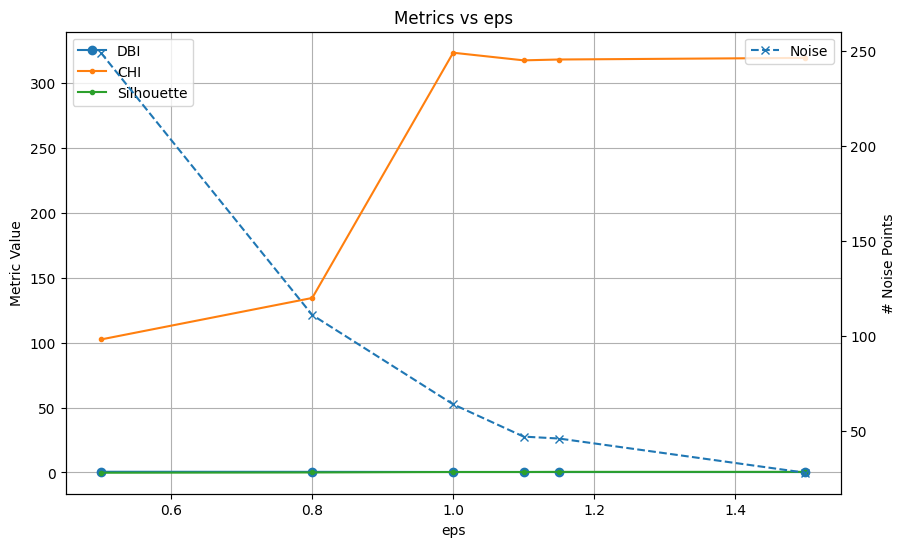

In [54]:
epses = [0.5, 0.8, 1.0, 1.1, 1.15, 1.5]

dbs = {eps: DBSCAN(eps=eps).fit(X) for eps in epses}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, dbs, epses)

plot_dbscan_metrics(epses, dbi, chi, silhouettes, noises, 'eps')

DBSCAN faces the expected trade-off: small `eps` isolates the peripheral clusters but fragments the cloud in more than one cluster with noise, whereas larger `eps` connects the clouds properly but starts including a peripheral cloud. One valid configuration is with `eps=1.1` that results in four clusters but also flags several noise candidates.

### 4.3.1. <a id='toc4_3_1_'></a>[DBSCAN as noise removal for K-Means](#toc0_)
Since DBSCAN identifies noise points that confuse K-Means. One option is to remove noise using DBSCAN and then apply K-Means to the cleaned dataset. This combines DBSCAN's noise reduction with K-Means' partitioning of the remaining structures (which shall be fairly convex).

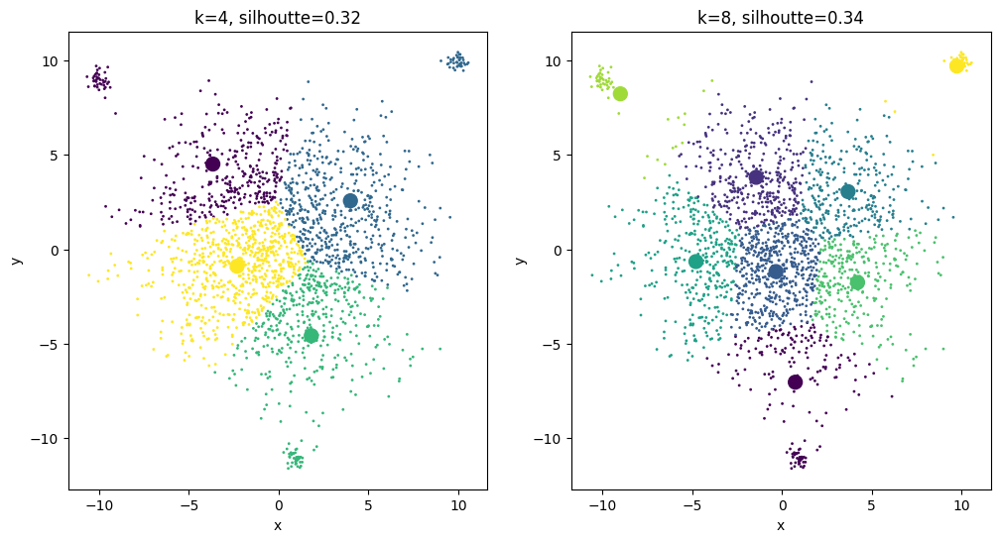

In [55]:
eps = 1.1
X_clean = X[labels[eps] != -1]

# K-Means on cleaned data (k=4)
ks = [4, 8]
_ = get_kmeans_metrics(X_clean, ks)

Using DBSCAN to remove noise and then running K-Means improves the silhouette score slightly (from 0.31 to 0.32 for `k=4`); however, it is still not able to identify the clusters properly.

## 4.4. <a id='toc4_4_'></a>[OPTICS](#toc0_)

,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,122,0.54,3240.64,0.54,1103
1,10,27,0.47,3644.65,0.67,1589
2,20,6,0.13,14613.50,0.91,1908
3,22,4,0.08,21537.20,0.95,1967
4,25,3,0.04,30819.88,0.97,1994
5,30,3,0.05,16644.97,0.96,1991
6,50,1,NaN,NaN,NaN,0


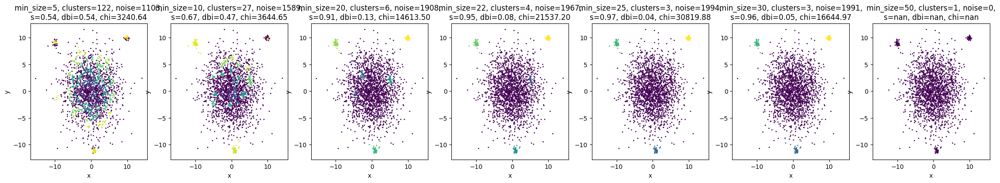

In [56]:
sizes = [5, 10, 20, 22, 25, 30, 50]

optics = {size: OPTICS(min_samples=size).fit(X) for size in sizes}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, optics, sizes, 'min_size')

OPTICS works poorly. More work is required to tune other parameters such as `xi`. Let's try other methods

## 4.5. <a id='toc4_5_'></a>[HDBSCAN](#toc0_)
Given the central cloud and the peripheral clouds have different densities, HDBSCAN is a good candidate to handle this dataset.

,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,0.36,316.23,0.46,22
1,10,5,0.47,280.58,0.24,122
2,12,4,0.37,340.41,0.39,81
3,20,4,0.37,340.41,0.39,81
4,40,4,0.37,340.41,0.39,81
5,100,2,0.72,470.24,0.53,1821


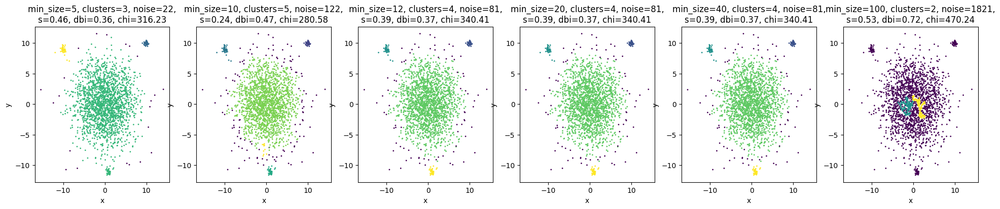

In [57]:
sizes = [5, 10, 12, 20, 40, 100]

hdbs = {size: HDBSCAN(min_cluster_size=size, min_samples=5).fit(X) for size in sizes}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, hdbs, sizes, 'min_size')

As expected, HDBSCAN works well by identifying four clusters with various reasonable values (between 10/12 to 40) of `min_cluster_size` implying the solution is **stable**.

## 4.6. <a id='toc4_6_'></a>[Spectral Clustering](#toc0_)
It is worth checking whether the affinity graph treats the peripheral clouds as distinct connected components or whether they get absorbed in the central cloud's graph.

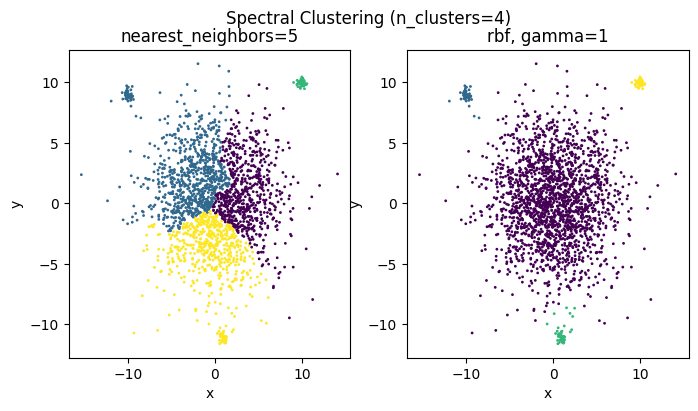

In [58]:
n_clusters = 4
n_neighbors = 5

configs = [
    {"affinity": "nearest_neighbors", "n_neighbors": n_neighbors},
    {"affinity": "rbf","gamma": 1},
]

sc_labels_all = plot_spectral_clustering(X, n_clusters, RANDOM_STATE, configs)

`rbf` affinity works well.

,gamma,Clusters,DBI,CHI,Silhouette,Noise
0,0.01,4,0.79,565.36,0.30,0
1,0.10,4,0.42,312.82,0.34,0
2,0.20,4,0.42,310.62,0.34,0
3,0.50,4,0.41,303.21,0.34,0
4,1.00,4,0.41,304.80,0.34,0
5,2.00,4,0.41,303.11,0.34,0


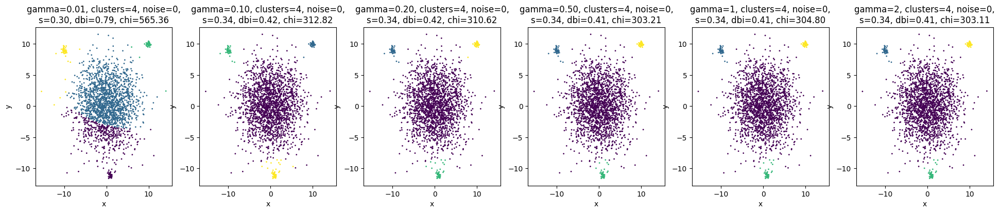

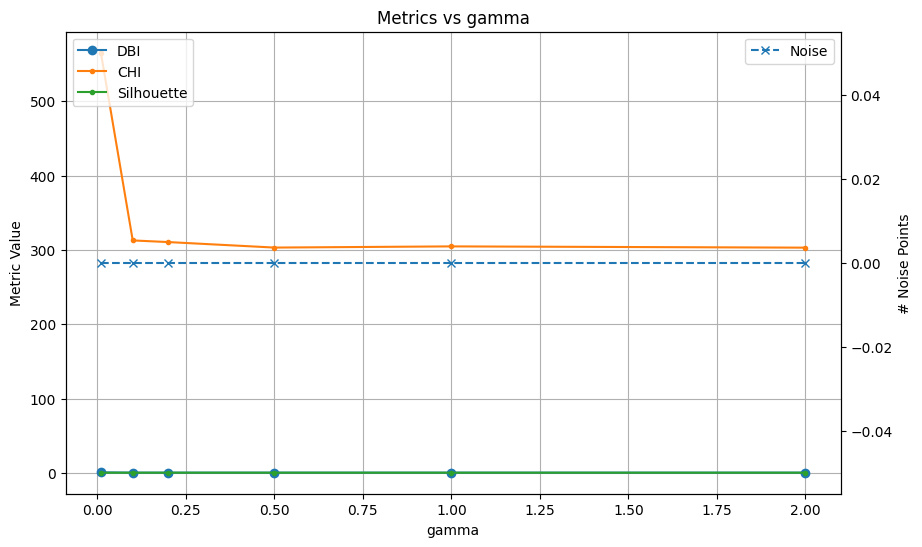

In [59]:
n_clusters = 4
aff = 'rbf'
gammas = [.01, .1, .2, .5, 1, 2]

models = {gamma: SpectralClustering(n_clusters=n_clusters, affinity=aff, gamma=gamma, random_state=RANDOM_STATE).fit(X) for gamma in gammas}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, models.keys(), 'gamma')

plot_dbscan_metrics(gammas, dbi, chi, silhouettes, noises, 'gamma')

Spectral gives **stable** results for `affinity=rbf` and various values of `gamma` (tested between .1 and 2)

## 4.7. <a id='toc4_7_'></a>[GMM](#toc0_)

The central cloud and peripheral clusters seems somewhat gaussian. So, let's see if GMM can separate them.

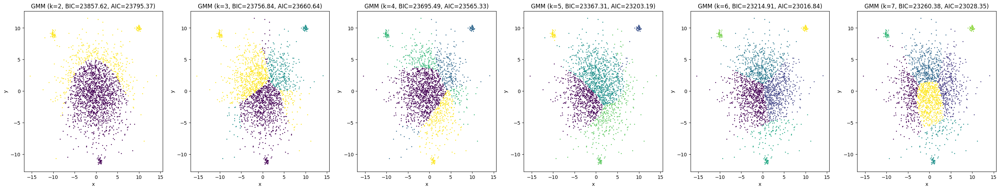

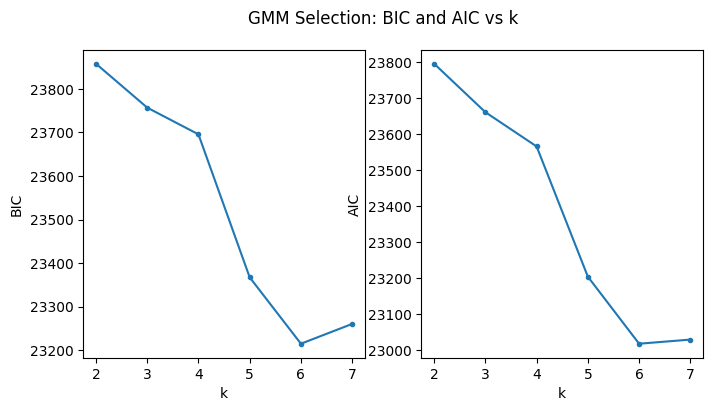

Best AIC score for k=6, score=23016.84
Best BIC score for k=6, score=23214.91


In [60]:
ks = range(2, 8)

gmms = {k: GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit(X) for k in ks}
labels, aics, bics, scores = get_plot_gmm_metrics(X, gmms)

GMM performs poorly, which is somewhat surprising. Seemingly, the diffuse cloud has high variance and is not well represented by a single Gaussian component, leading the model to split it into multiple components instead of preserving it as one cluster. Let's remove noise from the diffused cloud and try again.

### 4.7.1. <a id='toc4_7_1_'></a>[DBSCAN as noise removal for GMM](#toc0_)

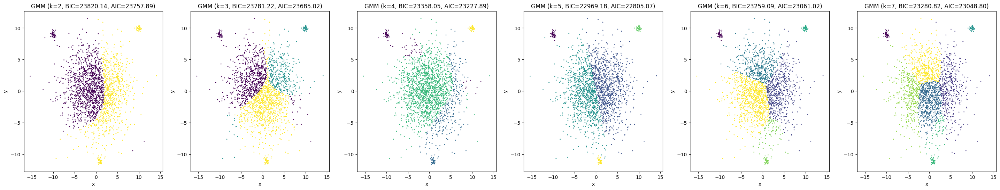

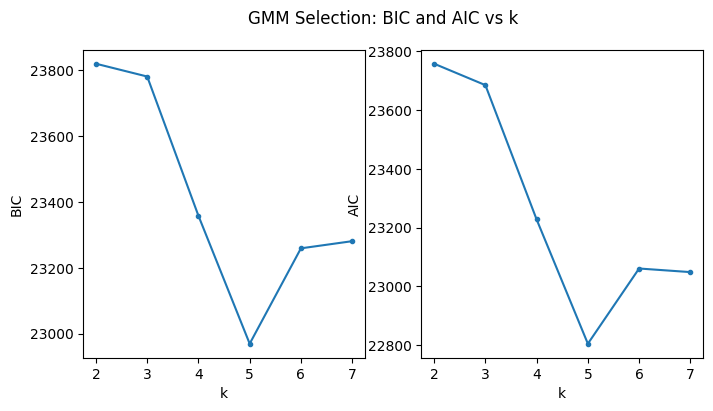

Best AIC score for k=5, score=22805.07
Best BIC score for k=5, score=22969.18


In [61]:
gmms = {k: GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit(X_clean) for k in ks}
labels, aics, bics, scores = get_plot_gmm_metrics(X, gmms)

Clustering improves for `k=4` considerably after noise-removal; however, it is still not ideal

## 4.8. <a id='toc4_8_'></a>[Agglomerative](#toc0_)

,linkage,Clusters,DBI,CHI,Silhouette,Noise
0,single,4,0.34,6.53,0.37,0
1,average,4,0.67,255.08,0.30,0
2,ward,4,1.00,908.67,0.29,0
3,complete,4,1.03,916.15,0.25,0


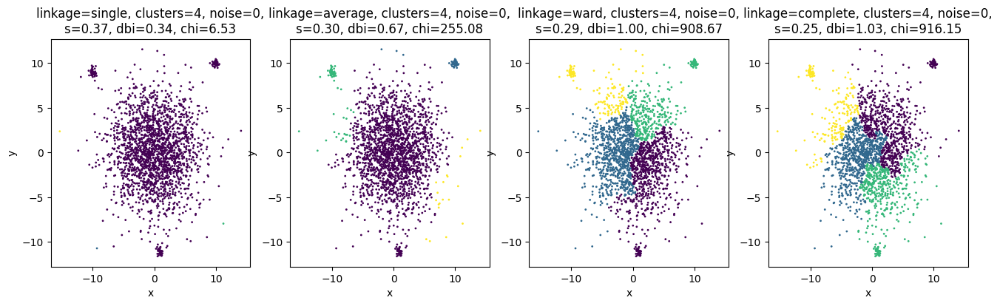

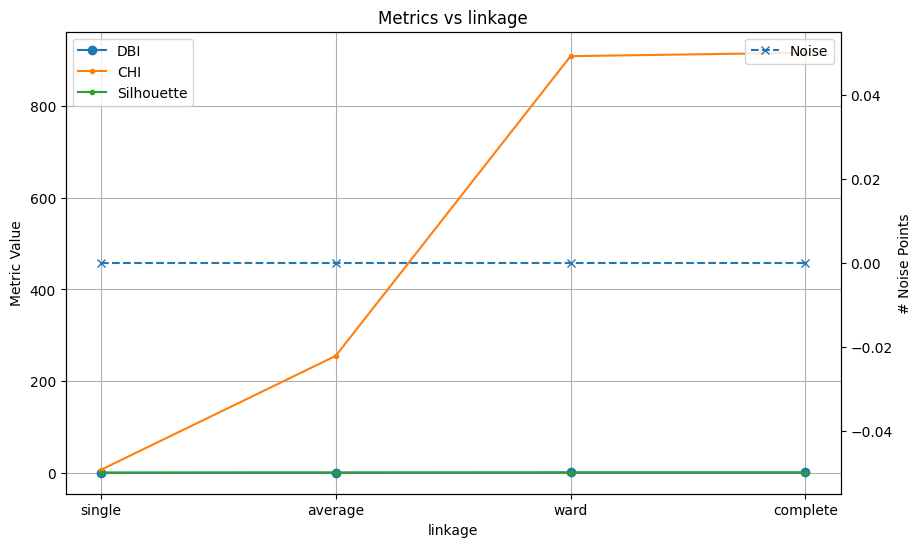

In [62]:
k = 4
linkages = ['single', 'average', 'ward', 'complete']
models = {link: AgglomerativeClustering(n_clusters=k, linkage=link).fit(X) for link in linkages}

labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, keys=models.keys(), key_name='linkage')

plot_dbscan_metrics(linkages, dbi, chi, silhouettes, noises, 'linkage')

Agglomerative fails to clearly capture the combination of density and distance based linkages for all four algorithms. This is somewhat expected as they rely on pair-wise distance and hierarchical merging, making them less effective on density based clusters.

## 4.9. <a id='toc4_9_'></a>[Conclusion](#toc0_)

Dataset 3 contains a large diffused cloud with smaller tighter peripheral groups and potential noise. This creates a challenge for centroid-based approaches because the largest cluster can dominate optimization.

| Model | Assessment | Verdict |
|---------|---------|---------|
| K-Means | Fast baseline but works poorly because larger cloud dominates distance optimizations | Rejected |
| GMM | Not effective as it is also influenced by dominant cloud | Rejected |
| DBSCAN | Successfully recovered non-convex structures while separating noise | Strong |
| OPTICS | Surprisingly doesn't work well. Need more tuning with other hyperparameters than `min_samples` | Rejected |
| Spectral | `affinity=rbf` performs well and provides stability if noise is not a consideration | Strong |
| HDBSCAN | Produced stable density-based clusters and handled noise robustly | Preferred |
| Agglomerative | All linkage methods fail to clearly capture both density and distance based linkage | Rejected |

**Preferred Model:** Spectral / HDBSCAN (or DBSCAN if simplicity is preferred).

Affinity and Density-based clustering produce acceptable cluster because they adapts naturally to local density variations and does not force all observations into predefined clusters.

# 5. <a id='toc5_'></a>[Dataset 4](#toc0_)

## 5.1. <a id='toc5_1_'></a>[Exploration](#toc0_)

,x,y
count,1100.000000,1100.000000
mean,0.011525,-1.910861
std,2.085843,3.568198
min,-3.953517,-7.386676
25%,-1.360428,-6.808515
50%,0.018785,-0.707936
75%,1.407206,0.533403
max,3.978353,3.654694


Shape: (1100, 2), x: (-3.95, 3.98), y: (-7.39, 3.65)


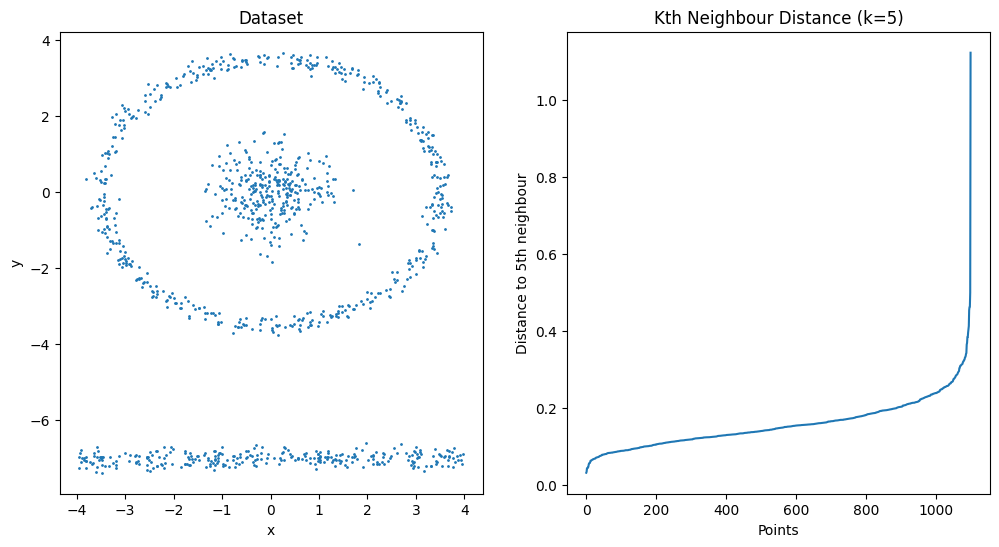

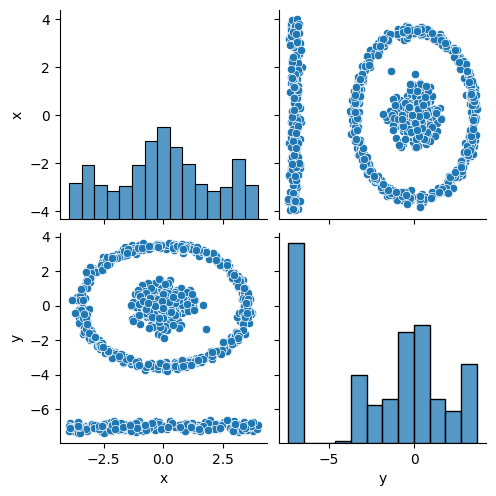

In [63]:
display(df4.describe())

X = df4[['x', 'y']].to_numpy()
explore_2d(X)

sns.pairplot(df4)
plt.show()

### 5.1.1. <a id='toc5_1_1_'></a>[Feature Scaling](#toc0_)

Shape: (1100, 2), x: (-1.90, 1.90), y: (-1.54, 1.56)


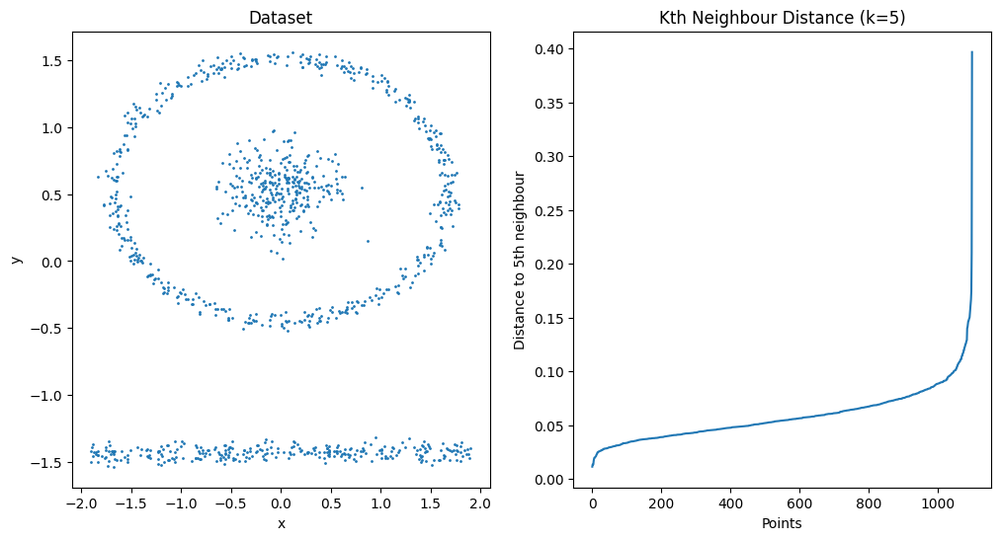

In [64]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

explore_2d(X_scaled)

### 5.1.2. <a id='toc5_1_2_'></a>[Observations](#toc0_)
- `y` has twice the range and 1.75x std of `x`, so, it makes sense to scale the dataset. This will ensure that `x` and `y` have equal contribution in distance-based methods.
- No missing or apparent anomalous data points.
- Data seems to be arranged in ring surrounding a disk (seems gaussian), and a stick. Assume clusters should follow the same shapes. Hence **three clusters**.
- Kth neighbour distance doesn't show abrupt elbow so we shall try different `eps` from 0.8 to 0.15
- Dataset `X_scaled` can be divided into two clear sections - where `y<-1` that can be assigned as one cluster, and `y>-1` can be further input to various clustering algorithms from **Dataset 1**

### 5.1.3. <a id='toc5_1_3_'></a>[Algorithm Strategy](#toc0_)
- **K-Means**: Baseline. Shall perform poorly (as in Dataset 1).
- **DBSCAN**: Good choice, somewhat uniform density within-cluster.
- **HDBSCAN**: Great choice, should work with varied density of ceontral blob.
- **Spectral**: Strong option. The graph connectivity should capture non-convex topologies
- **Agglomerative**: Good option. The hierarchical merging can respect these diverse shapes

In [65]:
X = X_scaled

No need to scale back for clustering representation

## 5.2. <a id='toc5_2_'></a>[K-Means](#toc0_)
For non-convex data, K-Means is expected to perform poorly.

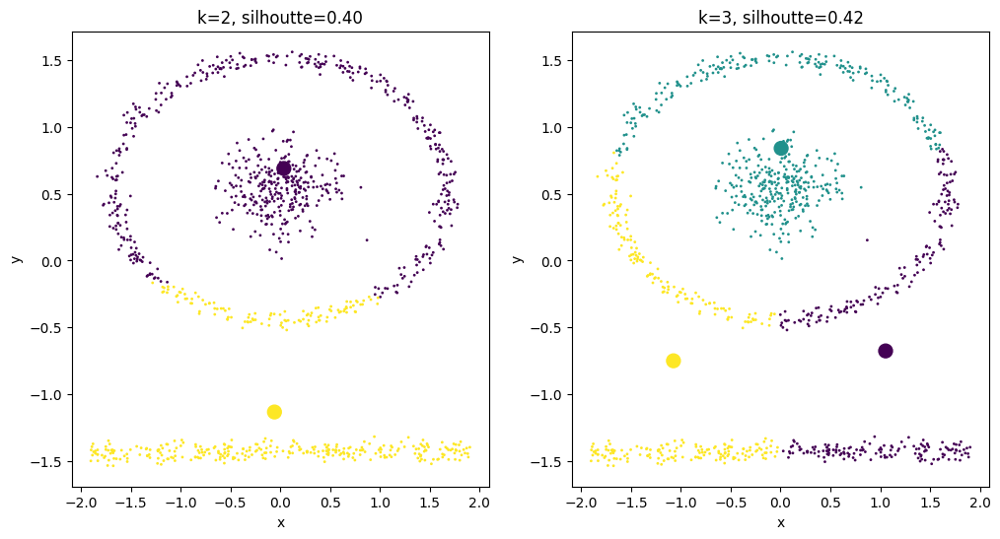

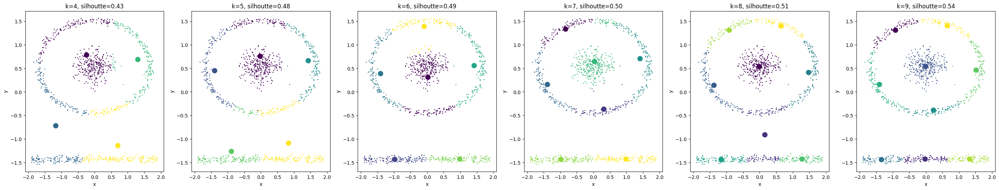

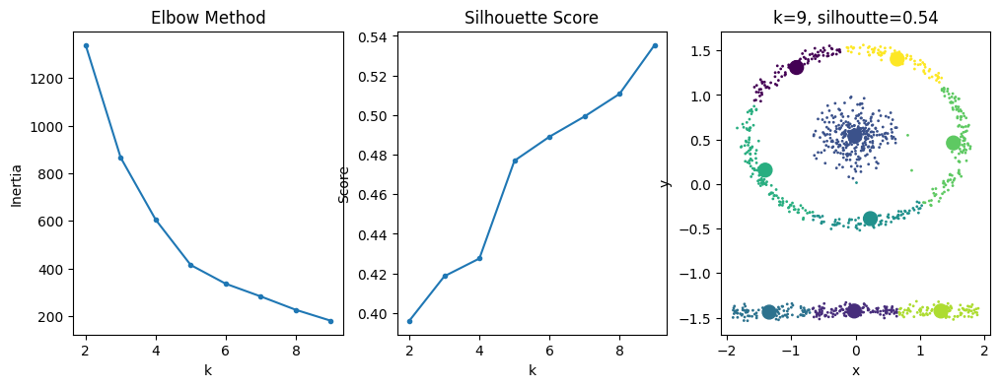

Highest silhouette score for k=9


In [66]:
ks = range(2, 10)

kms, labels, inertias, silhouettes = get_kmeans_metrics(X, ks, [2, 3])

small_ks = [k for k in ks if k != 2 and k != 3]
plot_kmeans(X, kms, silhouettes, small_ks)

find_plot_best_k(ks, X, kms, inertias, silhouettes)


As expected, K-Means is not able to cluster properly in the non-convex space.

## 5.3. <a id='toc5_3_'></a>[DBSCAN](#toc0_)
DBSCAN worked for visually similar **Dataset 1**, so let's see how it performs here. The density of ring and stick seem quite uniform, while the disk is slightly diffused.

,eps,Clusters,DBI,CHI,Silhouette,Noise
0,0.08,24,0.52,1029.69,0.41,53
1,0.10,5,0.97,478.42,0.31,23
2,0.12,3,42.51,339.69,0.21,5
3,0.15,3,39.47,341.05,0.21,2
4,0.20,3,43.74,341.31,0.21,1
5,0.40,2,0.98,683.18,0.43,0


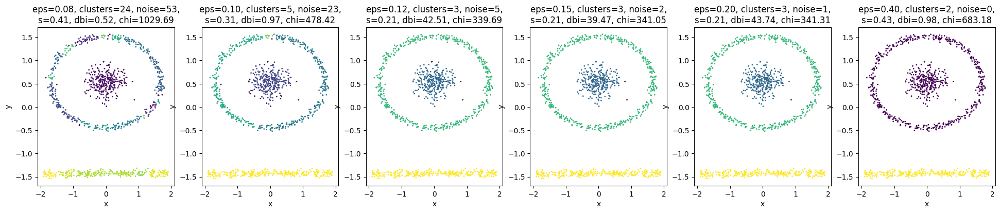

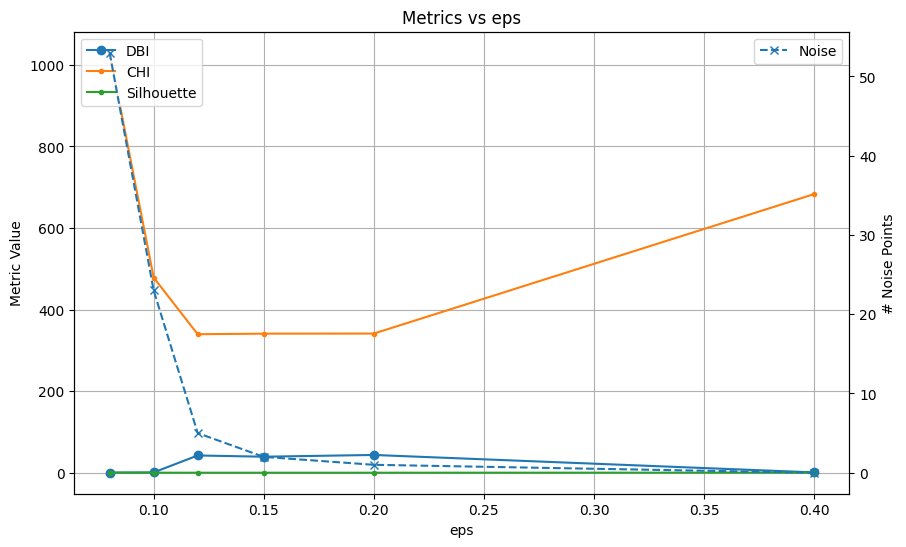

In [67]:
epses = [0.08, 0.1, 0.12, 0.15, 0.2, 0.4]

dbs = {eps: DBSCAN(eps=eps).fit(X) for eps in epses}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, dbs, epses)

plot_dbscan_metrics(epses, dbi, chi, silhouettes, noises, 'eps')

DBSCAN seems to work well in identifying the three clusters. `eps` needs to be more than the spacing within the ring and the disk while staying below the gap *between* them. As evident, going beyond .4, the clusters structure collapses and the ring and the disk are clubbed together as one cluster. Most suited values are between 0.12 and 0.2

## 5.4. <a id='toc5_4_'></a>[HDBSCAN](#toc0_)

To increase the stability of DBSCAN's clustering structure, we can try HDBSCAN.

,min_size,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,43.74,341.31,0.21,1
1,10,3,43.74,341.31,0.21,1
2,20,3,43.74,341.31,0.21,1
3,50,3,43.74,341.31,0.21,1
4,100,3,43.74,341.31,0.21,1


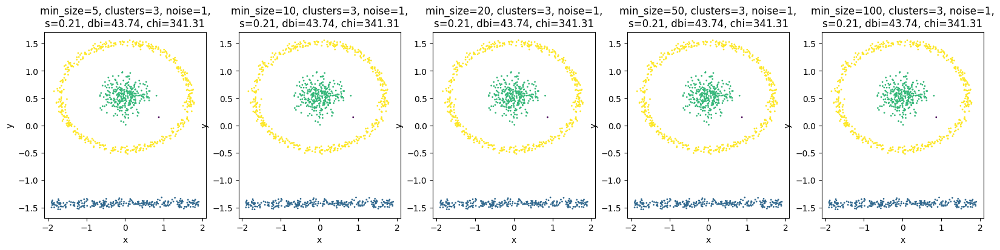

In [68]:
sizes = [5, 10, 20, 50, 100]

hdbs = {size: HDBSCAN(min_cluster_size=size, min_samples=5).fit(X) for size in sizes}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, hdbs, sizes, 'min_size')

As expected, HDBSCAN provides well-defined three clusters which stable for different values of `min_clsuter_size` (tested between 5 and 100).

## 5.5. <a id='toc5_5_'></a>[Spectral Clustering](#toc0_)

,neighbours,Clusters,DBI,CHI,Silhouette,Noise
0,5,3,1.36,66.62,-0.12,0
1,10,3,49.59,341.34,0.21,0
2,15,3,40.91,341.37,0.21,0
3,20,3,40.91,341.37,0.21,0
4,25,3,40.91,341.37,0.21,0
5,50,3,40.91,341.37,0.21,0


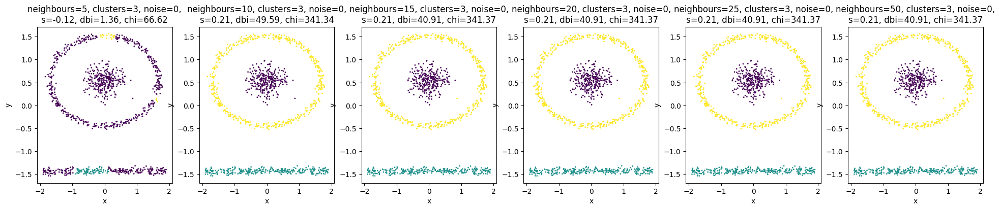

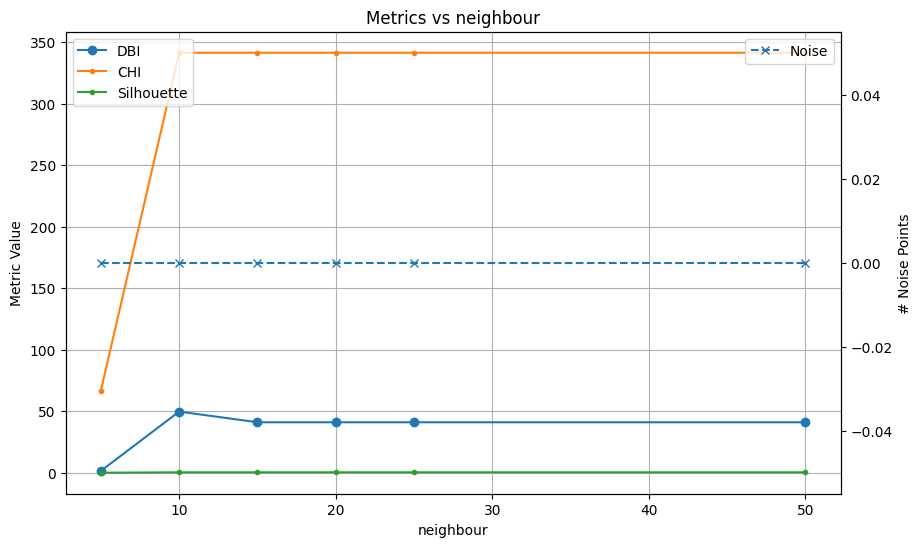

In [69]:
n_clusters = 3
aff = 'nearest_neighbors'
neighbours = [5, 10, 15, 20, 25, 50]

models = {n: SpectralClustering(n_clusters=n_clusters, affinity=aff, n_neighbors=n, random_state=RANDOM_STATE).fit(X) for n in neighbours}
labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, models.keys(), 'neighbours')

plot_dbscan_metrics(neighbours, dbi, chi, silhouettes, noises, 'neighbour')

Spectral Clustering also seems to work well. It gives **stable** results for `affinity=nearest_neighbors` (tested betweeen 10 and 50). The metrics are slightly misleading - silhouette score is low as the within-cluster distance could be extremely large for the diametrically opposite points on the ring. 

## 5.6. <a id='toc5_6_'></a>[Agglomerative](#toc0_)

,linkage,Clusters,DBI,CHI,Silhouette,Noise
0,single,3,40.91,341.37,0.21,0
1,complete,3,1.01,630.98,0.35,0
2,average,3,0.68,568.12,0.39,0
3,ward,3,0.97,714.20,0.38,0


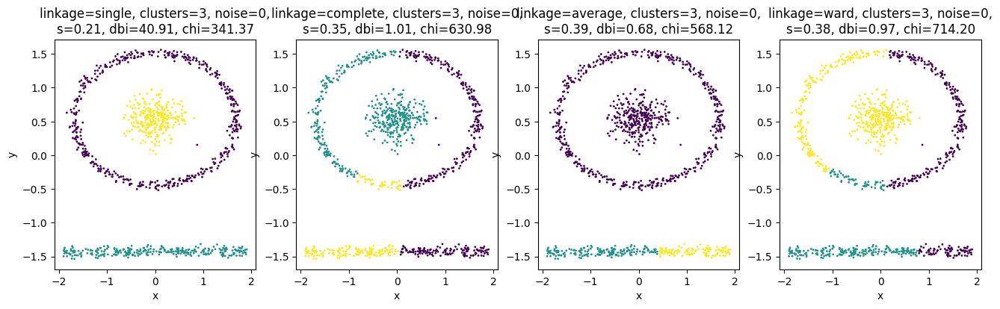

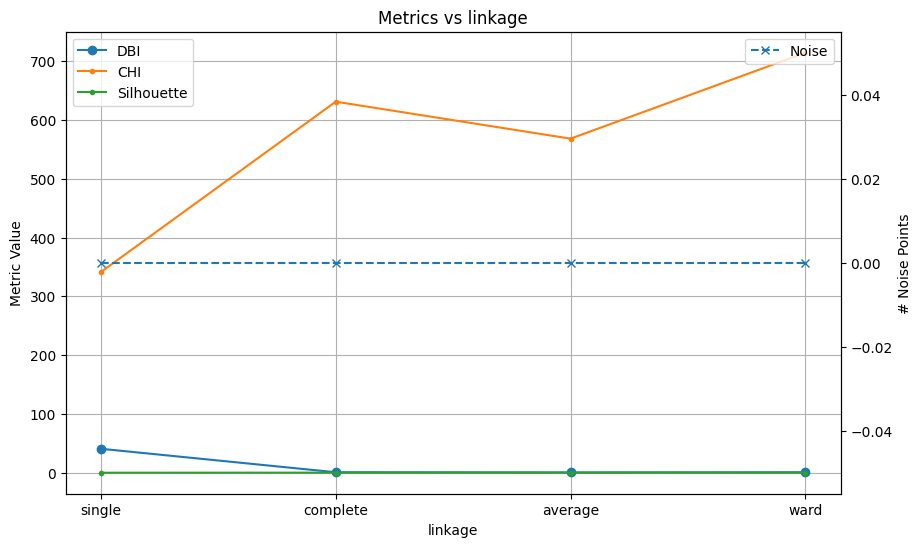

In [70]:
k = 3
linkages = ['single', 'complete', 'average', 'ward']
models = {link: AgglomerativeClustering(n_clusters=k, linkage=link).fit(X) for link in linkages}

labels, clusters, noises, silhouettes, dbi, chi = get_dbscan_metrics(X, models, keys=models.keys(), key_name='linkage')

plot_dbscan_metrics(linkages, dbi, chi, silhouettes, noises, 'linkage')

Agglomerative clustering gives the expected results. `single` linkage chains nearest neighbours, allowing it to follow connected structures and separate the three clusters since within-cluster distances remain smaller than inter-cluster distances. `complete` linkage fails because it uses the maximum pairwise distance, so both the ring and stick have large internal distances, which prevents them from being merged correctly. `ward` linkage splits clusters by minimizing variance, but the ring and stick have high intrinsic variance, causing them to be fragmented into smaller parts rather than preserved as single structures.

## 5.7. <a id='toc5_7_'></a>[Conclusion](#toc0_)

Dataset 4 seems similar of Dataset 1 but with a mix of convex structure in non-convex ones.

| Model | Assessment | Verdict |
|---------|---------|---------|
| K-Means | Fast baseline but works poorly because of non-convex structures | Rejected |
| DBSCAN | Successfully recovered non-convex structures while separating noise | Strong |
| Spectral | Performs Strongly and provides stable clustering results | Strong |
| HDBSCAN | Produced stable density-based clusters and handled noise robustly | Preferred |
| Agglomerative | All linkage methods fail except for `linkage=single` | Strong |

GMM and OPTICS are skipped as they haven't worked well for Dataset 1.

**Preferred Model:** Spectral / HDBSCAN (or DBSCAN if simplicity is preferred over stability).

Geometry is again better judge of model selection.

# 6. <a id='toc6_'></a>[Overall Results and Conclusions](#toc0_)

No single clustering algorithm performed best across all datasets. The datasets show that algorithm selection must driven by data geometry, density distribution and expected cluster shape (subject matter expertise).

| Dataset | Preferred Model | Rationale | Stability |
|----------|----------|----------|----------|
| Dataset 1 | HDBSCAN | Non-convex structures favour density-based clustering | Yes |
| Dataset 2 | GMM | Overlapping gaussian distributions | Largely Yes |
| Dataset 3 | Spectral / HDBSCAN | Local density variation with outlier handling | Yes |
| Dataset 4 | DBSCAN / HDBSCAN | Non-convex and diffused convex structures | Largely / Yes |

So overall
- **K-Means** expects convex clusters and works primarily as a baseline.
- **DBSCAN** excels on non-convex structures with meaningful density separation.
- **HDBSCAN** improves robustness over DBSCAN on datasets with multiple densities.
- **Spectral Clustering** is effective on complex non-linear structures.
- **GMM** provides useful probabilistic assignments and handles elliptical clusters better than K-Means.
- **Agglomerative Clustering** Hierarchical linkages depend on the algorithm used.

Evaluation metrics such as **Silhouette Score**, **Davies–Bouldin Index (DBI)** and **Calinski–Harabasz Index (CHI)** must be interpreted alongside visual observation because these may favour compact clusters over elongated or density-based structures, whch may be more meaningful. Likewise, **t-SNE** can be used as a visualisation aid (rather than a validation method). Additionally, we use **DBI**, **CHI**, and **Log-likelihood** to check how well GMM probabilstic results perform. 

Overall, the results demonstrate that understanding the dataset is more important than choosing a universally **best** algorithm. Density-based and graph-based methods were generally the strongest performers across the datasets.

# 7. <a id='toc7_'></a>[References](#toc0_)
## 7.1. <a id='toc7_1_'></a>[Libraries](#toc0_)

| Library | Use | Reference |
|----------|----------|----------|
| Jupyter | Interactive environment for python | Kluyver, T. et al. (2016), Project Jupyter, jupyter.org |
| ipykernel | Python kernel for notebook execution | Project Jupyter (2025), ipykernel.readthedocs.io |
| Matplotlib | Static visualisation and presentation of results | Hunter (2007), *Computing in Science & Engineering*, 9(3), 90–95. matplotlib.org |
| NumPy | Core numerical computations and experimental reproducibility | Harris et al. (2020), *Nature*, 585, 357–362. numpy.org |
| Pandas | Data handling and analysis workflows | McKinney (2010), *Proc. 9th Python in Science Conf.* pandas.pydata.org |
| Pandoc | Document converter - PDF | MacFarlane, J. (2025). Pandoc: a universal document converter. pandoc.org |
| Plotly | Interactive exploration of clustering structures | Plotly Technologies Inc. (2015). plotly.com |
| seaborn | Data visualization and exploratory data analysis | Michael L. Waskom (2014). Seaborn: Statistical Data Visualization |
| scikit-learn | Machine learning algorithms, validation metrics, and dimensionality reduction | Pedregosa et al. (2011), *JMLR*, 12, 2825–2830. scikit-learn.org |
| SciPy | Hierarchical clustering and scientific computing utilities | Virtanen et al. (2020), *Nature Methods*, 17, 261–272. scipy.org |

## 7.2. <a id='toc7_2_'></a>[Environment (pyproject.toml)](#toc0_)

<pre>
[project]
name = "cml"
version = "0.1.0"
description = "CML Assignment"
readme = "README.md"
requires-python = ">=3.14"
dependencies = [
    "ipykernel>=7.2.0",
    "jupyter>=1.1.1",
    "matplotlib>=3.10.9",
    "numpy>=2.4.4",
    "pandas>=3.0.2",
    "pandoc>=2.4",
    "plotly>=6.7.0",
    "seaborn>=0.13.2",
    "scikit-learn>=1.8.0",
    "scipy>=1.17.1",
]
</pre>

## 7.3. <a id='toc7_3_'></a>[Algorithms](#toc0_)

### 7.3.1. <a id='toc7_3_1_'></a>[Selection Rationale](#toc0_)

#### 7.3.1.1. <a id='toc7_3_1_1_'></a>[Algorithms Used](#toc0_)

- **K-Means** partitions data into k clusters by minimizing within-cluster variance. It is most appropriate for compact, approximately spherical clusters and serves as a useful baseline.
- **DBSCAN** groups points using density connectivity and identifies noise explicitly. It is suitable for non-convex structures where the number of clusters is not known in advance.
- **OPTICS** addresses varying densities but performs not as good as HDBSCAN.
- **HDBSCAN** extends DBSCAN by considering multiple density levels. It is useful when cluster densities vary across the dataset.
- **Spectral Clustering** uses graph connectivity rather than geometric distance alone, making it effective for non-linear cluster boundaries.
- **Gaussian Mixture Models (GMM)** provides probabilistic cluster assignments and models each cluster as a Gaussian.
- **Agglomerative Clustering** builds clusters hierarchically.

#### 7.3.1.2. <a id='toc7_3_1_2_'></a>[Algorithms Considered But Not Used](#toc0_)

- **MeanShift** was not included because does not provide clear advantages over DBSCAN/HDBSCAN for these datasets.
- **BIRCH** is primarily intended for very large datasets.
- **K-Medoids** is more robust to outliers than K-Means.
- **UMAP** is a dimensionality reduction and visualization technique similar to PCA and t-SNE.


### 7.3.2. <a id='toc7_3_2_'></a>[Computational Complexity](#toc0_)

| Algorithm | Time Complexity | Space Complexity | Notes |
|------------|----------------|------------------|-------|
| K-Means | O(n k i d) | O(n + k) | Fast baseline using simple centroid updates |
| GMM | O(n k  $d^2$ i) | O(k $d^2$) | Slower due to learning cluster shape (covariances) |
| DBSCAN | O(n log n) | O(n) | Efficient density-based clustering (with indexing) |
| HDBSCAN | O(n log n) to O($n^2$) | O($n^2$) | More robust and expensive DBSCAN variant |
| OPTICS | O(n log n) to O($n^2$) | O(n) to O($n^2$) | Produces reachability ordering; requires cluster extraction |
| Spectral Clustering | O($n^2$ to $n^3$) | O($n^2$) | Builds similarity graph |
| Agglomerative | O($n^2$ log n) | O($n^2$) | Builds clusters using pairwise distances |
| t-SNE | O($n^2$) | O(n) | Non-linear visualization |
| PCA | O(n $d^2$) | O($d^2$) | Dimensionality reduction using variance structure |

- *n* num of data points
- *d* num of features
- *k* num of clusters
- *i* num of iterations

### 7.3.3. <a id='toc7_3_3_'></a>[References](#toc0_)

| Algorithm | Use | Reference |
|------------|------------|------------|
| K-Means | Centroid-based clustering approach (convex) | Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Trans. Information Theory*, 28(2), 129–137 |
| DBSCAN | Density-based clustering with noise detection | Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). *Proc. KDD*, 226–231 |
| HDBSCAN | Hierarchical density-based clustering | Campello, R.J.G.B., Moulavi, D., & Sander, J. (2013). *PAKDD*, 160–172 |
| OPTICS | Ordering Points To Identify the Clustering Structure | Ankerst, M., Breunig, M.M., Kriegel, H.-P., & Sander, J. (1999). ACM SIGMOD, 49–60 |
| Spectral Clustering | Graph-based clustering of complex structures | Ng, A., Jordan, M., & Weiss, Y. (2001). *Advances in NIPS*, 14 |
| Agglomerative (Single) | Nearest-neighbor linkage clustering (chaining) | Sneath, P.H.A. (1957). J. Gen. Microbiol., 17, 201–226 |
| Agglomerative (Complete) | Max-distance linkage hierarchical clustering| Sørensen, T. (1948). Biol. Skrifter, 5(4), 1–34 |
| Agglomerative (Average) | Average linkage hierarchical clustering | Sokal, R.R., & Michener, C.D. (1958). Univ. Kansas Sci. Bull., 38, 1409–1438 |
| Agglomerative (Ward) | Variance-minimising hierarchical clustering, K-Means like | Ward, J.H. (1963). *JASA*, 58(301), 236–244 |
| GMM / EM | Probabilistic mixture modelling | Dempster, A.P., Laird, N.M., & Rubin, D.B. (1977). *JRSS Series B*, 39(1), 1–38 |
| PCA | Linear dimensionality reduction and variance analysis | Pearson, K. (1901). *Philosophical Magazine*, 2(11), 559–572 |
| t-SNE | Non-linear visualisation of high-dimensional manifold structure | van der Maaten, L., & Hinton, G. (2008). *JMLR*, 9, 2579–2605 |
| Silhouette Score | Assessment of cluster cohesion and separation | Rousseeuw, P.J. (1987). *Journal of Computational and Applied Mathematics*, 20, 53–65 |
| Davies-Bouldin Index | Assessment of cluster compactness and distinctness | Davies, D.L., & Bouldin, D.W. (1979). *IEEE TPAMI*, 1(2), 224–227 |
| Calinski-Harabasz Index | Variance-ratio based cluster evaluation | Calinski, T., & Harabasz, J. (1974). *Communications in Statistics*, 3(1), 1–27 |
| Adjusted Rand Index (ARI) | Measures similarity between two clusterings | Hubert, L., & Arabie, P. (1985). Journal of Classification, 2(1), 193–218 |